# Exercícios 4.1 – 4.13 — Semana 4: Communities and Seeing Networks

**Curso:** 02805 Social Graphs and Interactions (DTU, Fall 2026)
**Fonte:** [Week 4 page](https://sunelehmann.com/socialgraphs2026-web/weeks/week4.html) — "Communities and seeing networks"
**Livro:** Michele Coscia, *The Atlas for the Aspiring Network Scientist* (2ª ed., grátis em [networkatlas.eu](https://www.networkatlas.eu/)) — Ch. 35 (intro), Ch. 36 §36.1/36.4, Ch. 37 §37.1, Ch. 38 §38.3/38.5/38.7, Ch. 7 (weighted), Ch. 27 §27.1/27.5

Este notebook resolve os 13 exercícios da Semana 4, pela ordem da página do curso. O texto de cada
exercício é citado em bloco (inglês, tal como está no site) e a resposta vem a seguir, **em português**,
com derivação passo a passo nas partes matemáticas (uma linha por passo, cada truque nomeado). Os
exercícios 🧠 (à mão) são resolvidos em LaTeX e **verificados em código** logo a seguir; os 🔬 correm
sobre a rede dos filósofos (`data/`, release de 15 set 2026).

**Dados:** `week4_philosophers_nodes.tsv` / `week4_philosophers_edges.tsv` da [data page](https://sunelehmann.com/socialgraphs2026-web/data/).
1444 nós, 11 135 arestas dirigidas com peso; somando as duas direções: 9140 ligações não dirigidas, componente
gigante com **1374 nós e 9139 ligações** — exatamente os números da página, por isso os resultados
abaixo podem ser comparados diretamente com os do enunciado.

**Teste 1 — quarta 30 set, 08:30–09:30 (chegar 08:10), edifício 208 sala 054.** Os 🧠 desta semana
(4.1, 4.2, 4.3, 4.6-🧠, 4.7, 4.8, 4.10) têm a forma das perguntas do teste.

## Setup

In [1]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from itertools import combinations
from collections import Counter, defaultdict
from fractions import Fraction as Fr
from networkx.algorithms import community as nxc
from sklearn.metrics import normalized_mutual_info_score as nmi

plt.rcParams["figure.dpi"] = 100
SEED = 42

nodes = pd.read_csv("data/week4_philosophers_nodes.tsv", sep="\t", comment="#", quoting=3)
edges = pd.read_csv("data/week4_philosophers_edges.tsv", sep="\t", comment="#")

# rede não dirigida com peso = soma das duas direções (snippet da data page)
G_full = nx.Graph()
G_full.add_nodes_from(nodes.node_id)
for s, t, w in edges.itertuples(index=False):
    if G_full.has_edge(s, t):
        G_full[s][t]["weight"] += w
    else:
        G_full.add_edge(s, t, weight=w)

giant = G_full.subgraph(max(nx.connected_components(G_full), key=len)).copy()   # com pesos
GU = nx.Graph(giant.edges())                                                     # sem pesos

name = dict(zip(nodes.node_id, nodes.name))
era = dict(zip(nodes.node_id, nodes.era))
subf = dict(zip(nodes.node_id, nodes.subfields.fillna("none")))
desc = dict(zip(nodes.node_id, nodes.description.fillna("")))
deg = dict(GU.degree())
ORDER = list(GU.nodes())

print(f"dirigida:        n={len(nodes)}, arestas={len(edges)}, peso máx={edges.weight.max()}")
print(f"não dirigida:    {G_full}")
print(f"gigante:         {giant}")

def labels(partition, order=ORDER):
    # partição (lista de conjuntos) -> lista de rótulos pela ordem dada, para o sklearn
    lab = {n: i for i, c in enumerate(partition) for n in c}
    return [lab[n] for n in order]

def name_of(c, k=5):
    # os k membros de maior grau de uma comunidade
    return [name[n] for n in sorted(c, key=lambda n: -deg.get(n, 0))[:k]]

def degree_preserving_shuffle(G, seed, nswap_factor=10):
    Gs = G.copy()
    nswap = nswap_factor * Gs.number_of_edges()
    nx.double_edge_swap(Gs, nswap=nswap, max_tries=nswap * 20, seed=seed)
    return Gs

dirigida:        n=1444, arestas=11135, peso máx=18
não dirigida:    Graph with 1444 nodes and 9140 edges
gigante:         Graph with 1374 nodes and 9139 edges


## Exercício 4.1 — Cutting by hand (🧠 learn)

> Draw this network: nodes A–G, links A–B, A–C, B–C, C–D, D–E, D–F, E–F, F–G. (m=8.) Exercises 4.3 and 4.10 use it again.
>
> 1. Compute the edge betweenness of every link by counting. There are 21 pairs of nodes; for each pair find the shortest path and add 1 to every link on it (this network has no ties, so no pair has two shortest paths). Some links are quick: C–D carries every path between {A, B, C} and {D, E, F, G}. Which link does Girvan–Newman remove first?
> 2. Remove it and recompute. Which values changed? Explain in one sentence why F–G's value is now half what it was.
> 3. Remove the next link. Draw the first two levels of the dendrogram: which groups appear at level 1, and which at level 2?
> 4. Why does Girvan–Newman recompute after every removal instead of computing edge betweenness once and removing the links in that order? Point to the moment in the explorable where it matters.

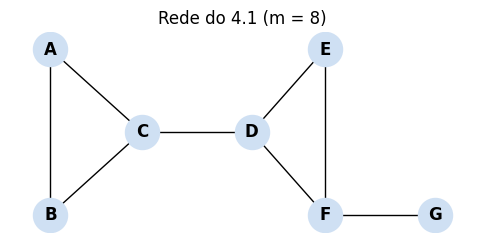

In [2]:
G41 = nx.Graph([("A","B"),("A","C"),("B","C"),("C","D"),("D","E"),("D","F"),("E","F"),("F","G")])
fig, ax = plt.subplots(figsize=(6, 2.6))
pos41 = {"A":(0,1),"B":(0,-1),"C":(1,0),"D":(2.2,0),"E":(3,1),"F":(3,-1),"G":(4.2,-1)}
nx.draw_networkx(G41, pos41, ax=ax, node_color="#cfe0f3", node_size=600, font_weight="bold")
ax.set_axis_off(); ax.set_title("Rede do 4.1 (m = 8)"); plt.show()

### 4.1.1 — Edge betweenness por contagem

Graus: $k_A=2,\ k_B=2,\ k_C=3,\ k_D=3,\ k_E=2,\ k_F=3,\ k_G=1$. A rede é duas "ilhas" — o triângulo
$\{A,B,C\}$ e o bloco $\{D,E,F,G\}$ — unidas pela única ponte C–D.

**Truque 1 — ponte única entre dois grupos carrega $n_1 \cdot n_2$ caminhos.** Todo o par com um nó de
cada lado tem de passar por C–D:
$$
\text{EB}(C\text{–}D) = |\{A,B,C\}| \cdot |\{D,E,F,G\}| = 3 \cdot 4 = 12
$$

**Truque 2 — folha (grau 1) ⇒ a sua ligação carrega todos os caminhos dela.** G só chega aos outros
6 nós por F–G, e ninguém mais usa F–G (não há ninguém "atrás" de G):
$$
\text{EB}(F\text{–}G) = n - 1 = 6
$$

**D–F.** Pares que o usam: $G$ com $\{A,B,C,D\}$ (4 pares: G→F→D→…) e $F$ com $\{A,B,C,D\}$ (4 pares).
E–G? O caminho mais curto é E–F–G (2 passos), não usa D–F. Logo
$$
\text{EB}(D\text{–}F) = 4 + 4 = 8
$$

**D–E.** Pares: $E$ com $\{A,B,C,D\}$ (o caminho de E para o lado esquerdo vai E–D, 1 passo, melhor que E–F–D):
$$
\text{EB}(D\text{–}E) = 4
$$

**E–F.** Só $E$–$F$ e $E$–$G$:
$$
\text{EB}(E\text{–}F) = 2
$$

**A–C (e, por simetria A↔B, também B–C).** A chega a C e a tudo o que está à direita de C por A–C:
$\{C, D, E, F, G\}$ = 5 pares:
$$
\text{EB}(A\text{–}C) = \text{EB}(B\text{–}C) = 5
$$

**A–B.** Só o par $A$–$B$:
$$
\text{EB}(A\text{–}B) = 1
$$

**Verificação — cada par contribui com o seu comprimento.** A soma de todas as EB é igual à soma de todas
as distâncias:
$$
12+8+6+5+5+4+2+1 = 43 = \sum_{i<j} d_{ij}
$$
(verificado em código abaixo). **Girvan–Newman remove primeiro C–D (EB = 12).**

### 4.1.2 — Remover C–D e recalcular

Agora há dois componentes; só pares **dentro** de cada componente contam.

- Triângulo $\{A,B,C\}$: cada ligação só carrega o seu próprio par ⇒ A–B = A–C = B–C = **1**.
- Bloco $\{D,E,F,G\}$ (4 nós, 6 pares): F–G = **3** (G com D, E, F); D–F = **2** (D–F, D–G); E–F = **2** (E–F, E–G); D–E = **1**.

Mudaram **todas** as ligações exceto A–B e E–F (A–C, B–C: 5→1; D–F: 8→2; D–E: 4→1; F–G: 6→3).
Soma nova $=1+1+1+3+2+2+1 = 11$ (= soma das distâncias dentro dos componentes).

**Porque é que F–G passa a metade (6 → 3):** F–G carrega exatamente um caminho por cada nó que G consegue
alcançar; antes eram os outros 6 nós, agora só D, E, F — os 3 do triângulo ficaram do outro lado do corte.

### 4.1.3 — Segunda remoção e dendrograma

O máximo é agora F–G (3) ⇒ remove-se F–G, e G fica isolado.
- **Nível 0 (raiz):** $\{A,B,C,D,E,F,G\}$
- **Nível 1** (após cortar C–D): $\{A,B,C\}\ \cdot\ \{D,E,F,G\}$
- **Nível 2** (após cortar F–G): $\{A,B,C\}\ \cdot\ \{D,E,F\}\ \cdot\ \{G\}$

```
            {A,B,C,D,E,F,G}
             /           \
       {A,B,C}         {D,E,F,G}        <- nível 1 (corte C–D)
          |             /      \
       {A,B,C}      {D,E,F}    {G}      <- nível 2 (corte F–G)
```

### 4.1.4 — Porque recalcular depois de cada remoção

Porque cada corte **redistribui o tráfego**: os caminhos que usavam a ligação cortada mudam para outras
(ou desaparecem, se o par ficou desligado). Os valores antigos deixam de descrever a rede nova. Se
calculássemos uma vez só e cortássemos pela ordem inicial (C–D, D–F, F–G, …), o segundo corte seria
**D–F** (8 no cálculo inicial) — uma ligação *interna* do bloco direito — quando, depois de recalcular,
D–F vale só 2 e o corte certo é F–G. O caso típico em que isto importa é o de **duas pontes paralelas**
entre dois grupos: cada uma leva ~metade do tráfego; corta-se uma, e a outra passa a levar **tudo**.
No explorable da Secção 2 é exatamente o que se vê no readout: à medida que as pontes rareiam, as que
sobram carregam cada vez mais (no corte 13 o valor máximo passa de 1000), e o corte 15 — a última
ponte entre o grupo de 68 e o de 32 — carrega exatamente $68 \times 32 = 2176$; logo a seguir à
separação os valores recalculados caem para 183. Sem recalcular, essa última ponte teria o valor
inicial baixo (partilhado) e nunca seria a primeira da fila.

In [3]:
# Verificação do 4.1
def eb(G):
    return {tuple(sorted(e)): v for e, v in nx.edge_betweenness_centrality(G, normalized=False).items()}

eb0 = eb(G41)
print("EB inicial:", dict(sorted(eb0.items(), key=lambda x: -x[1])))
print("soma EB =", sum(eb0.values()), "  soma distâncias =",
      sum(d for u, dd in nx.all_pairs_shortest_path_length(G41) for v, d in dd.items() if u < v))

H = G41.copy(); H.remove_edge("C", "D")
eb1 = eb(H); print("após cortar C–D:", dict(sorted(eb1.items(), key=lambda x: -x[1])))
nxt = max(eb1, key=eb1.get); H.remove_edge(*nxt)
print("segundo corte:", nxt, "-> componentes:", [sorted(c) for c in nx.connected_components(H)])

# o mesmo com a implementação do networkx
gn = nxc.girvan_newman(G41)
print("girvan_newman nível 1:", [sorted(c) for c in next(gn)])
print("girvan_newman nível 2:", [sorted(c) for c in next(gn)])

EB inicial: {('C', 'D'): 12.0, ('D', 'F'): 8.0, ('F', 'G'): 6.0, ('A', 'C'): 5.0, ('B', 'C'): 5.0, ('D', 'E'): 4.0, ('E', 'F'): 2.0, ('A', 'B'): 1.0}
soma EB = 43.0   soma distâncias = 43
após cortar C–D: {('F', 'G'): 3.0, ('D', 'F'): 2.0, ('E', 'F'): 2.0, ('A', 'B'): 1.0, ('A', 'C'): 1.0, ('B', 'C'): 1.0, ('D', 'E'): 1.0}
segundo corte: ('F', 'G') -> componentes: [['A', 'B', 'C'], ['D', 'E', 'F'], ['G']]
girvan_newman nível 1: [['A', 'B', 'C'], ['D', 'E', 'F', 'G']]
girvan_newman nível 2: [['A', 'B', 'C'], ['D', 'E', 'F'], ['G']]


## Exercício 4.2 — Did you really read it? — groups (🧠 learn)

> No notebook, no chatbot. Think, then write.
>
> 1. Define a community in one sentence, then explain why "the nodes that are all connected to each other" is not a good definition (what would it say about the philosophers?).
> 2. Why does modularity subtract $k_ik_j/2m$? What would go wrong if you scored a partition by the fraction of links inside communities alone? (Hint: what does that fraction give when everyone is in one community?)
> 3. In the karate club, Louvain's four groups score higher than the real two factions. Does that mean the four groups are "more real"? What does it mean?
> 4. A friend reports "modularity 0.35, so the network has community structure." List the two questions you would ask before believing it.

### 4.2.1 — Definição

**Comunidade:** um conjunto de nós mais densamente ligados entre si do que ao resto da rede (na versão
do Coscia: se dois nós estão na mesma comunidade, é mais provável que estejam ligados).

"Todos ligados a todos" é a definição de **clique** — é demasiado estrita. Nos filósofos, a tradição grega
tem centenas de membros e nenhum grupo desse tamanho é completo (Heraclito não tem ligação a todos os
estoicos romanos, etc.): a maior clique da rede é pequena, por isso essa definição partiria as grandes
escolas em pedacinhos ou deixaria quase todos os filósofos sem comunidade. Uma comunidade real é densa
*relativamente* ao resto, não completa.

### 4.2.2 — Porque subtrair $k_ik_j/2m$

Sem o termo nulo, o score seria apenas a fração de ligações dentro das comunidades,
$\sum_c \ell_c / m$. Pondo **todos numa só comunidade**, essa fração é
$$
\frac{\ell_{\text{tudo}}}{m} = \frac{m}{m} = 1,
$$
o máximo possível — o score "premiaria" sempre a partição trivial (e, em geral, comunidades maiores).
O termo $k_ik_j/2m$ é o número esperado de ligações entre $i$ e $j$ num modelo de configuração (mesmos
graus, ligações ao acaso); subtraí-lo mede **quantas ligações a mais do que o acaso** ficam dentro dos
grupos. Com uma só comunidade, o esperado também é tudo:
$$
Q_{\text{tudo}} = \frac{m}{m} - \left(\frac{2m}{2m}\right)^2 = 1 - 1 = 0.
$$
E usa-se o nulo que preserva graus porque os hubs têm muitas ligações "por acaso" — não se quer contar
como estrutura de grupo o que é só efeito do grau.

### 4.2.3 — Quatro grupos do Louvain vs duas facções reais

Não, não são "mais reais". $Q$ mais alto só diz que a partição em 4 é **mais agrupada** (mais ligações
internas acima do esperado) — cada facção tinha um círculo interno, e partir cada uma em dois ganha
modularidade. Modularidade mede *quão agrupada* é uma partição, não *quão certa* é; não há "verdade"
dentro do número. A pergunta "quais eram os grupos reais" só a responde informação externa (quem
seguiu quem na cisão) — e, mesmo aí, há razões fora da rede (o aluno a 3 semanas do cinturão negro).

### 4.2.4 — Duas perguntas antes de acreditar em "Q = 0.35"

1. **Comparado com quê?** Qual é o $Q$ que o mesmo algoritmo encontra na mesma rede baralhada com graus
   preservados (o nulo)? Uma rede aleatória esparsa pode dar $Q = 0.35$ ou mais; só o excesso sobre o nulo
   (ou um $z$-score) diz se há estrutura.
2. **É estável?** Quantas corridas/seeds? Qual é o NMI entre partições de corridas diferentes? Um $Q$ alto
   com NMI baixo entre corridas é um score sem estrutura por trás.

## Exercício 4.3 — Modularity by hand (🧠 learn)

> Use the network from exercise 4.1 (m=8).
>
> 1. Compute Q for the partition {A, B, C} · {D, E, F, G} using the per-community formula: for each group, count the links inside it and add up its members' degrees.
> 2. Compute Q for the partition {A, B, C, D} · {E, F, G}. Which of the two is better, and by how much? Explain in one sentence, from the network drawing, why.
> 3. Compute Q for level 2 of your dendrogram from exercise 4.1. Which level of the dendrogram would Newman and Girvan cut at?
> 4. Compute Q for "everything in one community." Then argue, without computing, whether any partition of this network can score below that.
> 5. Node G has degree 1. Show that moving G into the same community as F always raises Q. (This is the reason community detection sticks leaves to their only neighbor.)

Fórmula por comunidade, com $m = 8$, $2m = 16$, $(2m)^2 = 256$:
$$
Q = \sum_c \left[\frac{\ell_c}{m} - \left(\frac{d_c}{2m}\right)^2\right]
$$
Graus: $A{=}2,\ B{=}2,\ C{=}3,\ D{=}3,\ E{=}2,\ F{=}3,\ G{=}1$ (soma $=16=2m$ ✓).

**Truque — denominador comum 256:** $\ \dfrac{\ell_c}{8} = \dfrac{32\,\ell_c}{256}$ e $\ \left(\dfrac{d_c}{16}\right)^2 = \dfrac{d_c^2}{256}$, logo
$$
Q = \frac{1}{256}\sum_c \left(32\,\ell_c - d_c^2\right).
$$

### 4.3.1 — $\{A,B,C\} \cdot \{D,E,F,G\}$

- $\{A,B,C\}$: ligações internas A–B, A–C, B–C ⇒ $\ell = 3$; $d = 2+2+3 = 7$.
- $\{D,E,F,G\}$: D–E, D–F, E–F, F–G ⇒ $\ell = 4$; $d = 3+2+3+1 = 9$. (Verificação: $7 + 9 = 16$ ✓; $3+4 = 7$ internas + 1 a cruzar (C–D) $= 8$ ✓.)

$$
\begin{aligned}
Q_1 &= \frac{1}{256}\Big[(32\cdot 3 - 7^2) + (32\cdot 4 - 9^2)\Big] \\
    &= \frac{1}{256}\Big[(96 - 49) + (128 - 81)\Big] \\
    &= \frac{47 + 47}{256} \\
    &= \frac{94}{256} = \frac{47}{128} \approx 0.367
\end{aligned}
$$

### 4.3.2 — $\{A,B,C,D\} \cdot \{E,F,G\}$

- $\{A,B,C,D\}$: A–B, A–C, B–C, C–D ⇒ $\ell = 4$; $d = 2+2+3+3 = 10$.
- $\{E,F,G\}$: E–F, F–G ⇒ $\ell = 2$; $d = 2+3+1 = 6$. (Cruzam D–E e D–F: 2 ligações.)

$$
\begin{aligned}
Q_2 &= \frac{1}{256}\Big[(128 - 100) + (64 - 36)\Big] \\
    &= \frac{28 + 28}{256} \\
    &= \frac{56}{256} = \frac{7}{32} \approx 0.219
\end{aligned}
$$

A primeira é melhor por $\ Q_1 - Q_2 = \dfrac{94 - 56}{256} = \dfrac{38}{256} \approx 0.148$.
**Porquê (pelo desenho):** a primeira corta só a ponte C–D (1 ligação), enquanto a segunda arranca D do
triângulo D–E–F e corta 2 ligações (D–E, D–F), pondo D junto de um grupo ao qual só tem 1 ligação.

### 4.3.3 — Nível 2 do dendrograma: $\{A,B,C\} \cdot \{D,E,F\} \cdot \{G\}$

- $\{A,B,C\}$: $\ell=3,\ d=7$ ⇒ $96 - 49 = 47$
- $\{D,E,F\}$: $\ell=3$ (D–E, D–F, E–F), $d = 3+2+3 = 8$ ⇒ $96 - 64 = 32$
- $\{G\}$: $\ell = 0,\ d = 1$ ⇒ $0 - 1 = -1$

$$
Q_{\text{nível 2}} = \frac{47 + 32 - 1}{256} = \frac{78}{256} = \frac{39}{128} \approx 0.305
$$

Comparando os níveis: nível 0 (tudo junto) $Q=0$; nível 1 $Q \approx 0.367$; nível 2 $Q \approx 0.305$.
Newman e Girvan cortam o dendrograma no **nível 1** (máximo de $Q$).

### 4.3.4 — Tudo numa comunidade, e pode haver pior?

$$
Q_{\text{tudo}} = \frac{32\cdot 8 - 16^2}{256} = \frac{256 - 256}{256} = 0
$$

**Sim, há partições com $Q < 0$.** Argumento sem contas: separar nós que estão ligados tira ligações de
dentro (o termo positivo desce) e parte o termo nulo em pedaços. O exemplo extremo são **todos os nós
sozinhos**: não há nenhuma ligação interna, logo $Q = -\sum_i (k_i/2m)^2 < 0$ estritamente (cada termo é
um quadrado positivo). Qualquer partição que ponha vizinhos em grupos diferentes e não-vizinhos juntos
fica abaixo de zero — "pior que o acaso".

### 4.3.5 — Mover a folha G para junto de F aumenta sempre $Q$

Seja $a$ a comunidade de G (sem F) e $b$ a comunidade de F. Chamemos $d_a'$ à soma dos graus de $a$
**sem** G, e $d_b$ à soma dos graus de $b$. G tem grau 1 e o seu único vizinho está em $b$.

Antes do movimento (só escrevo os termos que mudam):
$$
Q_{\text{antes}} \ni -\left(\frac{d_a' + 1}{2m}\right)^2 - \left(\frac{d_b}{2m}\right)^2 \qquad (\text{G não traz ligações internas a } a)
$$
Depois: a ligação F–G passa a ser interna a $b$ (ganha $1/m$) e o grau de G muda de $a$ para $b$:
$$
Q_{\text{depois}} \ni \frac{1}{m} - \left(\frac{d_a'}{2m}\right)^2 - \left(\frac{d_b + 1}{2m}\right)^2
$$
Diferença — **truque: $(x+1)^2 - x^2 = 2x + 1$**, os "+1" cancelam:
$$
\begin{aligned}
\Delta Q &= \frac{1}{m} + \frac{(d_a'+1)^2 - d_a'^2 - \big[(d_b+1)^2 - d_b^2\big]}{4m^2} \\
         &= \frac{1}{m} + \frac{(2d_a' + 1) - (2d_b + 1)}{4m^2} \\
         &= \frac{1}{m} + \frac{d_a' - d_b}{2m^2} \\
         &= \frac{2m - d_b + d_a'}{2m^2}
\end{aligned}
$$
Como $b$ não contém G, $d_b \le 2m - 1$ (falta pelo menos o "stub" de G), logo $2m - d_b \ge 1$ e
$$
\Delta Q \ \ge\ \frac{1 + d_a'}{2m^2} \ >\ 0 .
$$
Portanto **colar a folha ao seu único vizinho aumenta sempre $Q$**, seja qual for o resto da partição.
Exemplo aqui: de $\{A,B,C\}\cdot\{D,E,F\}\cdot\{G\}$ para $\{A,B,C\}\cdot\{D,E,F,G\}$: $d_a' = 0$,
$d_b = 8$, $\Delta Q = \frac{16 - 8 + 0}{2\cdot 64} = \frac{8}{128} = \frac{16}{256}$, e de facto
$\frac{78}{256} + \frac{16}{256} = \frac{94}{256}$ ✓.

In [4]:
# Verificação do 4.3 (frações exatas)
def Q_frac(G, parts):
    m = G.number_of_edges(); total = Fr(0)
    for c in parts:
        l = G.subgraph(c).number_of_edges(); d = sum(dict(G.degree(c)).values())
        total += Fr(l, m) - Fr(d, 2*m)**2
    return total

for P in [[set("ABC"), set("DEFG")], [set("ABCD"), set("EFG")],
          [set("ABC"), set("DEF"), {"G"}], [set("ABCDEFG")],
          [{n} for n in "ABCDEFG"]]:
    q = Q_frac(G41, P)
    print(f"{[''.join(sorted(c)) for c in P]!s:40s} Q = {q} = {float(q):.4f}   networkx: {nxc.modularity(G41, P):.4f}")

# 4.3.5: G sozinho vs G com F, para TODAS as partições do resto {A..F} (teste exaustivo)
def set_partitions(items):
    if not items: yield []; return
    first, rest = items[0], items[1:]
    for p in set_partitions(rest):
        for i in range(len(p)):
            yield p[:i] + [p[i] | {first}] + p[i+1:]
        yield p + [{first}]

worst = min(
    nxc.modularity(G41, [c | {"G"} if "F" in c else c for c in p]) - nxc.modularity(G41, p + [{"G"}])
    for p in set_partitions(list("ABCDEF")))
print(f"\nmenor ganho ΔQ ao juntar G a F (sobre as {sum(1 for _ in set_partitions(list('ABCDEF')))} partições de A–F): {worst:.4f} > 0")

['ABC', 'DEFG']                          Q = 47/128 = 0.3672   networkx: 0.3672
['ABCD', 'EFG']                          Q = 7/32 = 0.2188   networkx: 0.2188
['ABC', 'DEF', 'G']                      Q = 39/128 = 0.3047   networkx: 0.3047
['ABCDEFG']                              Q = 0 = 0.0000   networkx: 0.0000
['A', 'B', 'C', 'D', 'E', 'F', 'G']      Q = -5/32 = -0.1562   networkx: -0.1562

menor ganho ΔQ ao juntar G a F (sobre as 203 partições de A–F): 0.0078 > 0


## Exercício 4.4 — Thousands of modularity papers? (🚀 builder, opcional)

> Use your agentic powers to find out, and end with a number you can defend. [...] use OpenAlex [...]
>
> 1. Count three ways and compare: all text (`search=modularity`), titles only (`filter=title.search:modularity`), and titles and abstracts that also name the method (`filter=title_and_abstract.search:modularity AND "community detection"`). How far apart are the answers?
> 2. 🔬 Validate before you believe: pull 20 random hits from each query (`sample=20&seed=1`) and read the titles. What fraction is about modularity in our sense? [...] Turn that into an estimate with an honest range.
> 3. A different definition: count the papers that cite Newman and Girvan's 2004 paper [...] and do the same for the Louvain paper. Which count answers my question better, and what does each one miss? Add `group_by=publication_year` [...]: is modularity a finished topic or a live one?

A célula seguinte faz as consultas (sem chave; ~10 pedidos). Se a API não responder, usa os valores
guardados a **23 set 2026**, que são os que estão comentados abaixo.

In [5]:
import json, urllib.request, urllib.parse
OA = "https://api.openalex.org/"
CACHE = {  # resultados de 2026-09-23
    "all": 1_659_995, "title": 135_562, "ta": 3_256, "cites_NG2004": 14_278, "cites_Louvain": 21_583,
    "sample_relevant": {"all": 1, "title": 0, "ta": 19},
}
def oa(path):
    with urllib.request.urlopen(OA + path, timeout=20) as r:
        return json.load(r)

queries = {
    "all":   "works?search=modularity",
    "title": "works?filter=title.search:modularity",
    "ta":    "works?filter=title_and_abstract.search:" + urllib.parse.quote('modularity AND "community detection"'),
}
try:
    counts = {k: oa(q + "&per-page=1")["meta"]["count"] for k, q in queries.items()}
    samples = {k: [w["display_name"] for w in oa(q + "&sample=20&seed=1&per-page=20&select=display_name")["results"]]
               for k, q in queries.items()}
    ng = oa("works/doi:10.1103/PhysRevE.69.026113?select=id")["id"].split("/")[-1]
    lv = oa("works/doi:10.1088/1742-5468/2008/10/P10008?select=id")["id"].split("/")[-1]
    counts["cites_NG2004"] = oa(f"works?filter=cites:{ng}&per-page=1")["meta"]["count"]
    counts["cites_Louvain"] = oa(f"works?filter=cites:{lv}&per-page=1")["meta"]["count"]
    per_year = {g["key"]: g["count"] for g in oa(f"works?filter=cites:{ng}&group_by=publication_year")["group_by"]}
    for k, titles in samples.items():
        print(f"\n--- amostra '{k}' ---"); print("\n".join("  " + t for t in titles))
except Exception as e:
    print("OpenAlex indisponível -> valores em cache de 2026-09-23:", e)
    counts = {k: v for k, v in CACHE.items() if k != "sample_relevant"}
    per_year = {2004:37,2005:59,2006:118,2007:255,2008:300,2009:410,2010:521,2011:615,2012:671,2013:806,2014:859,
                2015:809,2016:901,2017:827,2018:1010,2019:1011,2020:926,2021:922,2022:852,2023:724,2024:673,2025:639,2026:323}
print("\ncontagens:", counts)


--- amostra 'all' ---
  Software agents and intelligent object fusion
  Bioinspired Low-Frequency Material Characterisation
  A Sequence Prediction Algorithm Integrating Knowledge Graph Embedding and Dynamic Evolution Process
  Állattenyésztés és takarmányozás 73.
  Multiplicity free and completely reducible tensor products for $\mathrm{SL}_3(\Bbbk)$ and $\mathrm{Sp}_4(\Bbbk)$
  Diagnosis of Intermittently Faulty Units at System Level
  Basic Research Needs for Microelectronics: Report of the Office of Science Workshop on Basic Research Needs for Microelectronics, October 23 – 25, 2018
  Семейный уровень профилактики психического дизонтогенеза у детей
  An evolutionary basis for protein design and structure prediction
  Foreword to "Concentrated Corporate Ownership"
  A guide to the major commercial AI issues and concerns
  A Cognitive Approach to Adaptive Radar Systems and Intelligent Vehicles
  Expression and Assembly of Active Human Telomerase in Escherichia coli
  Implementation o

**Resultados (23 set 2026):**

| Contagem | nº de trabalhos | na amostra de 20, sobre modularidade *nossa* |
|---|---:|---:|
| texto completo `search=modularity` | 1 659 995 | 1/20 |
| só títulos `title.search:modularity` | 135 562 | 0/20 |
| título+resumo com "community detection" | 3 256 | 19/20 |
| citam Newman & Girvan 2004 (define $Q$) | 14 278 | — |
| citam Blondel et al. 2008 (Louvain) | 21 583 | — |

**4.4.1 — Quão longe estão?** Três ordens de grandeza (de ~3 mil a ~1.7 milhões). As duas primeiras são
inúteis tal como estão: o motor faz *stemming*, e "modularity" apanha **modular, modules, modularity** em
todos os sentidos — conversores multinível modulares, reatores modulares pequenos, construção modular,
formas modulares em matemática, estruturas modulares de piroxenas... Na amostra de títulos, 0 em 20 eram
sobre modularidade de redes.

**4.4.2 — Estimativa com intervalo honesto.**
- Consulta "título+resumo com community detection": 19/20 relevantes ⇒ fração $\hat p = 0.95$; intervalo de
  Wilson a 95% para $n=20$: $\approx [0.76,\ 0.99]$ ⇒ **~2 500 – 3 200 artigos**. Isto é um **limite
  inferior**: exige a frase exata "community detection", e perde artigos que usam modularidade em redes
  cerebrais ("modular organization", "modularity of brain networks") ou em redes biológicas sem essa frase.
- Consulta de texto completo: 1/20 ⇒ intervalo de Wilson $\approx [0.01,\ 0.24]$ ⇒ entre ~15 mil e ~400 mil.
  Com 20 amostras o intervalo é enorme — não serve para uma estimativa, só para mostrar o ruído.

**4.4.3 — Citações como definição.** ~14 300 trabalhos citam o artigo que definiu $Q$ e ~21 600 citam o
Louvain. Isto responde melhor à pergunta "quantos artigos *sobre/usando* modularidade", mas cada contagem
falha de forma diferente: citar Newman–Girvan 2004 não implica que o artigo seja *sobre* modularidade
(muitos citam-no de passagem), e perde quem usa $Q$ citando outra fonte (o livro do Newman, a revisão do
Fortunato); citar o Louvain apanha sobretudo **utilizadores** do algoritmo (biologia, neurociência,
single-cell RNA...), não investigação sobre modularidade. **Número defensável:** "da ordem de dezenas de
milhares de artigos usam modularidade; alguns milhares são *sobre* detecção de comunidades por modularidade"
— portanto o "thousands of papers" do Sune está certo, e é até conservador.

**Tópico vivo ou encerrado?** As citações anuais do artigo de 2004 sobem até um pico ~2018–2019 (~1000/ano)
e descem lentamente desde então (~640 em 2025) — mas a consulta "modularity AND community detection" em
título+resumo **continua a crescer** (389 em 2026 até setembro, o máximo de sempre). Leitura: o *conceito*
tornou-se infraestrutura (já não se cita o original), mas o tema continua vivo, sobretudo em aplicações.

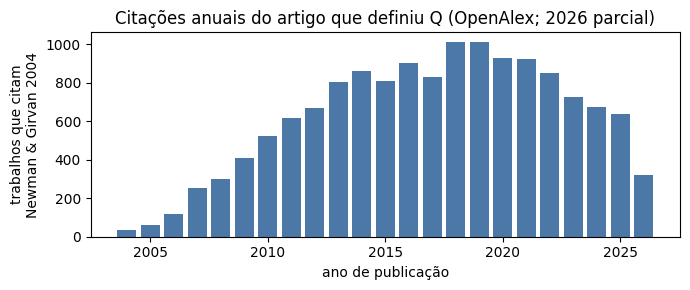

In [6]:
yrs = sorted(k for k in per_year if int(k) >= 2004)
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar([int(y) for y in yrs], [per_year[y] for y in yrs], color="#4c78a8")
ax.set_xlabel("ano de publicação"); ax.set_ylabel("trabalhos que citam\nNewman & Girvan 2004")
ax.set_title("Citações anuais do artigo que definiu Q (OpenAlex; 2026 parcial)")
plt.tight_layout(); plt.savefig("figs/4.4_citations_per_year.png", dpi=150); plt.show()

## Exercício 4.5 — Louvain on the philosophers, as code (🔬 tool)

> 1. Load the philosophers network, take the giant component of the undirected version, and run `networkx.community.louvain_communities`. Report the number of communities and Q. Check that your numbers are in this page's range.
> 2. For each community print its five highest-degree members, then name it in a few words. Which groups are easy to name? Which ones resist? Then compute the NMI between your partition and the era column, and between your partition and the subfields column (use "none" for the empty ones). Which label does the partition know more about?
> 3. Run Louvain again with five different seeds. Report the number of communities and Q for each. Then compute the NMI between every pair of runs and show the 5 × 5 matrix. What is the lowest agreement between two runs of the same algorithm on the same data? Which philosophers change community most often?
> 4. Run `networkx.community.greedy_modularity_communities` (Newman's greedy merging) on the same network. Report the communities, Q, and the NMI against your Louvain run, and explain from the two algorithms' descriptions why greedy merging scores lower.
> 5. 🔬 Have your agent implement phase 1 of Louvain from the description above (no community package), run it on the karate club, and validate that its Q equals what `networkx.community.modularity` reports for the same partition. Then make it explain why its partition can differ from networkx's and still be "correct."

In [7]:
# 4.5.1 -- Louvain (não ponderado) no componente gigante
P0 = nxc.louvain_communities(GU, seed=0)
P0 = sorted(P0, key=len, reverse=True)
Q0 = nxc.modularity(GU, P0)
print(f"seed 0: {len(P0)} comunidades, Q = {Q0:.4f}   tamanhos: {[len(c) for c in P0]}")

seed 0: 9 comunidades, Q = 0.5061   tamanhos: [263, 220, 214, 213, 181, 104, 90, 83, 6]


**4.5.1.** 9 comunidades com $Q = 0.506$ — dentro do intervalo da página (8–10 comunidades,
$Q \in [0.500, 0.508]$) e igual ao valor final do explorable ($Q = 0.506$).

In [8]:
# 4.5.2 -- os 5 membros de maior grau de cada comunidade
for i, c in enumerate(P0):
    print(f"[{i}] {len(c):3d} | " + ", ".join(name_of(c, 5)))

[0] 263 | Immanuel Kant, Georg Wilhelm Friedrich Hegel, Friedrich Nietzsche, Baruch Spinoza, Karl Marx
[1] 220 | René Descartes, Gottfried Wilhelm Leibniz, John Locke, David Hume, Isaac Newton
[2] 214 | Aristotle, Plato, Cicero, Diogenes Laertius, Heraclitus
[3] 213 | Thomas Aquinas, Augustine of Hippo, Jesus, Dante Alighieri, Martin Luther
[4] 181 | Bertrand Russell, John Stuart Mill, Henri Bergson, William James, Albert Einstein
[5] 104 | The Buddha, Adi Shankara, Rabindranath Tagore, Madhvacharya, Nagarjuna
[6]  90 | Avicenna, Averroes, Maimonides, Al-Ghazali, Al-Farabi
[7]  83 | Confucius, John Dewey, Zhu Xi, Mao Zedong, Mencius
[8]   6 | Władysław Tatarkiewicz, Feliks Koneczny, Hugo Kołłątaj, Jan Śniadecki, Józef Maria Hoene-Wroński


**Nomes (a partir dos 5 de maior grau, e espreitando mais membros):**

| # | tamanho | líderes | nome |
|---|---:|---|---|
| 0 | 263 | Kant, Hegel, Nietzsche, Spinoza, Marx | Filosofia alemã (idealismo → Marx/Nietzsche) + Spinoza |
| 1 | 220 | Descartes, Leibniz, Locke, Hume, Newton | Início da modernidade / Iluminismo e revolução científica |
| 2 | 214 | Aristóteles, Platão, Cícero, Diógenes Laércio, Heraclito | Antiguidade greco-romana |
| 3 | 213 | Tomás de Aquino, Agostinho, Jesus, Dante, Lutero | Pensamento cristão (Patrística → Escolástica → Renascimento) |
| 4 | 181 | Russell, Mill, Bergson, William James, Einstein | Séc. XIX tardio / fundadores da filosofia do séc. XX |
| 5 | 104 | Buda, Adi Shankara, Tagore, Madhvacharya, Nagarjuna | Filosofia indiana |
| 6 | 90 | Avicena, Averróis, Maimónides, Al-Ghazali, Al-Farabi | Filosofia islâmica e judaica medieval |
| 7 | 83 | Confúcio, John Dewey, Zhu Xi, Mao Zedong, Laozi | Filosofia chinesa (+ Dewey, que esteve na China 1919–21) |
| 8 | 6 | Tatarkiewicz, Koneczny, Kołłątaj, Śniadecki, Staszic | Iluminismo/filosofia polaca (um pequeno aglomerado isolado) |

**Fáceis:** as tradições não-europeias (indiana, chinesa, islâmica) e a Antiguidade — são grupos com
fronteiras linguísticas/culturais nítidas. **Resistem:** as comunidades 0, 1 e 4 misturam critérios
(Spinoza cai com os alemães, Newton com os filósofos, Einstein com Russell); a 3 junta Galileu (6º membro de maior grau) a Aquino;
e mesmo a 7 tem "intrusos" (Dewey). O nome é um rótulo que *nós* contamos depois — não um resultado.

In [9]:
lab_era = [era[n] for n in ORDER]
lab_sub = [subf[n] for n in ORDER]
print(f"NMI(partição, era)      = {nmi(labels(P0), lab_era):.3f}")
print(f"NMI(partição, subfields) = {nmi(labels(P0), lab_sub):.3f}")
print("\nsubfields: ", Counter(lab_sub).most_common(4))

NMI(partição, era)      = 0.404
NMI(partição, subfields) = 0.091

subfields:  [('none', 1052), ('social and political philosophers', 58), ('metaphysicians', 54), ('logicians', 51)]


A partição sabe muito mais sobre a **era** (NMI ≈ 0.40, igual à página) do que sobre os **subfields**
(NMI ≈ 0.09). Faz sentido: as ligações da Wikipédia seguem **tradições** (quem leu/comentou quem, ao longo
do tempo e da geografia), e isso correlaciona com o século; já "ético", "lógico", "metafísico" atravessam
todas as tradições — há lógicos gregos, escolásticos, indianos e alemães. Nota: 1119 de 1444 filósofos (1052 dos 1374 do gigante)
não estão em nenhuma lista de subcampo ("none"), o que também puxa o NMI para baixo.

In [10]:
# 4.5.3 -- cinco seeds
runs = {}
for s in range(5):
    P = nxc.louvain_communities(GU, seed=s)
    runs[s] = P
    print(f"seed {s}: {len(P):2d} comunidades, Q = {nxc.modularity(GU, P):.4f}")

S = list(runs)
M = np.array([[nmi(labels(runs[a]), labels(runs[b])) for b in S] for a in S])
print("\nNMI entre corridas:\n", pd.DataFrame(M, index=[f"s{s}" for s in S], columns=[f"s{s}" for s in S]).round(3))
off = M[np.triu_indices(5, 1)]
print(f"\nmín = {off.min():.3f}, máx = {off.max():.3f}, média = {off.mean():.3f}")

seed 0:  9 comunidades, Q = 0.5061
seed 1:  9 comunidades, Q = 0.5045
seed 2:  8 comunidades, Q = 0.5068
seed 3:  8 comunidades, Q = 0.4862
seed 4:  7 comunidades, Q = 0.5014

NMI entre corridas:
        s0     s1     s2     s3     s4
s0  1.000  0.781  0.765  0.656  0.740
s1  0.781  1.000  0.760  0.711  0.743
s2  0.765  0.760  1.000  0.655  0.693
s3  0.656  0.711  0.655  1.000  0.703
s4  0.740  0.743  0.693  0.703  1.000

mín = 0.655, máx = 0.781, média = 0.721


In [11]:
# Quem muda mais de comunidade? Alinha cada corrida à de referência (seed 0) pela maior sobreposição,
# e conta em quantas das outras 4 corridas o filósofo NÃO está na "mesma" comunidade.
ref = {n: i for i, c in enumerate(runs[0]) for n in c}
def align(P):
    # cada comunidade de P -> comunidade de referência com quem mais partilha nós
    out = {}
    for c in P:
        best = Counter(ref[n] for n in c).most_common(1)[0][0]
        for n in c: out[n] = best
    return out
moves = Counter()
for s in S[1:]:
    al = align(runs[s])
    for n in ORDER:
        if al[n] != ref[n]: moves[n] += 1
print(f"filósofos que mudam em ≥1 corrida: {sum(1 for n in ORDER if moves[n] > 0)} de {len(ORDER)}")
print(f"filósofos que mudam em todas as 4: {sum(1 for n in ORDER if moves[n] == 4)}")
top_movers = sorted(ORDER, key=lambda n: (-moves[n], -deg[n]))[:15]
print("\nos que mais mudam (desempate: grau):")
for n in top_movers:
    seq = [" / ".join(name_of(next(c for c in runs[s] if n in c), 1)) for s in S]
    print(f"  {name[n]:32s} grau {deg[n]:3d}  muda {moves[n]}x  líder da comunidade em cada seed: {seq}")

filósofos que mudam em ≥1 corrida: 587 de 1374
filósofos que mudam em todas as 4: 67

os que mais mudam (desempate: grau):
  John Stuart Mill                 grau  74  muda 4x  líder da comunidade em cada seed: ['Bertrand Russell', 'René Descartes', 'René Descartes', 'John Locke', 'René Descartes']
  Charles Darwin                   grau  57  muda 4x  líder da comunidade em cada seed: ['Bertrand Russell', 'Immanuel Kant', 'René Descartes', 'Friedrich Nietzsche', 'Immanuel Kant']
  Thomas Carlyle                   grau  43  muda 4x  líder da comunidade em cada seed: ['Bertrand Russell', 'Immanuel Kant', 'René Descartes', 'Friedrich Nietzsche', 'Immanuel Kant']
  John Dewey                       grau  35  muda 4x  líder da comunidade em cada seed: ['Confucius', 'Bertrand Russell', 'Bertrand Russell', 'Immanuel Kant', 'Immanuel Kant']
  Auguste Comte                    grau  34  muda 4x  líder da comunidade em cada seed: ['Bertrand Russell', 'Immanuel Kant', 'René Descartes', 'Friedrich N

**4.5.3.** O número de comunidades varia entre 7 e 9 e $Q$ entre 0.486 e 0.507 — e, no entanto, o NMI
entre corridas desce até **0.655** (a página dá 0.65–0.83 sobre 45 pares). 587 dos 1374 filósofos mudam de
comunidade em pelo menos uma corrida; 67 mudam em todas. Os que mais mudam são os **de fronteira**:
- pensadores britânicos/americanos do séc. XIX — Mill, Darwin, Carlyle, Comte, Huxley, Emerson, Whewell,
  De Morgan — que oscilam entre os grupos de Russell, Descartes e Kant (o séc. XIX não tem "casa" própria);
- filósofos naturais do séc. XVII e do Renascimento — Mersenne, Gassendi, Paracelso — entre Descartes,
  Aristóteles e Aquino (ainda escolásticos, já modernos);
- pontes culturais — Dewey (esteve na China) e Tagore — entre as tradições asiáticas e as ocidentais.

Os hubs não mudam: o que se move são as margens entre tradições.
Uma seed (a 3) chega a $Q \approx 0.486$, abaixo do intervalo da página: é uma lembrança de que o Louvain é
guloso e nem sempre sobe tão alto.

In [12]:
# 4.5.4 -- greedy merging (Clauset-Newman-Moore)
PG = sorted(nxc.greedy_modularity_communities(GU), key=len, reverse=True)
print(f"greedy: {len(PG)} comunidades, Q = {nxc.modularity(GU, PG):.4f}")
print(f"NMI(greedy, Louvain seed 0) = {nmi(labels(PG), labels(P0)):.3f}\n")
for i, c in enumerate(PG):
    print(f"[{i:2d}] {len(c):3d} | " + ", ".join(name_of(c, 5)))

greedy: 15 comunidades, Q = 0.4162
NMI(greedy, Louvain seed 0) = 0.500

[ 0] 550 | Immanuel Kant, Georg Wilhelm Friedrich Hegel, René Descartes, Friedrich Nietzsche, Gottfried Wilhelm Leibniz
[ 1] 481 | Aristotle, Plato, Thomas Aquinas, Cicero, Augustine of Hippo
[ 2] 262 | Heraclitus, Bertrand Russell, Edmund Husserl, Henri Bergson, Plotinus
[ 3]  20 | Joseph Glanvill, Franciscus Mercurius van Helmont, Henry More, Margaret Cavendish, Duchess of Newcastle-upon-Tyne, Jacques Rohault
[ 4]  15 | Abu al-Hasan al-Ash'ari, Al-Shafi'i, Abu Hanifa, Dawud al-Zahiri, Ahmad ibn Hanbal
[ 5]  14 | Nikolay Lossky, Vladimir Solovyov (philosopher), Pavel Florensky, Nikolai Fyodorov (philosopher), Aleksei Losev
[ 6]   8 | Cesare Cremonini (philosopher), Justus Lipsius, Giovanni Botero, Juan de Mariana, John Ray
[ 7]   6 | Hans Kelsen, Jerome Frank, Karl Llewellyn, Roscoe Pound, Karl Renner
[ 8]   5 | Władysław Tatarkiewicz, Hugo Kołłątaj, Jan Śniadecki, Józef Maria Hoene-Wroński, Stanisław Staszic
[ 9]

**4.5.4.** 15 comunidades, $Q = 0.416$ (a página: 15 e 0.416), com três blobs de 550, 481 e 262 — um deles
junta Heraclito e Plotino a Russell e Einstein — e uma dúzia de grupinhos. NMI com o Louvain ≈ 0.50.

**Porque o greedy fica abaixo:** o greedy só sabe **fundir** comunidades, e uma fusão **nunca se desfaz**.
Fusões precoces que pareciam boas (grandes hubs juntam-se cedo, porque $\Delta Q = \ell_{ab}/m - 2 d_a d_b/(2m)^2$
é grande quando há muitas ligações entre eles) fazem bola de neve: o blob cresce, e os nós que ficaram no
blob errado não têm maneira de sair. O Louvain, na fase 1, **move nós individuais** entre comunidades
vizinhas repetidamente até nenhum movimento melhorar $Q$ — corrige os erros de afetação — e só depois
agrega; na fase seguinte move *grupos* inteiros. Tem mais "graus de liberdade" para subir na paisagem.

In [13]:
# 4.5.5 -- fase 1 do Louvain escrita de raiz (sem pacote de comunidades), validada contra networkx
def louvain_phase1(G, seed=0, max_sweeps=100):
    """Move nós, um de cada vez, para a comunidade vizinha que mais aumenta Q; repete até uma
    varrida inteira não mover ninguém. Devolve a lista de comunidades."""
    rng = np.random.default_rng(seed)
    m = G.number_of_edges()
    k = dict(G.degree())
    comm = {n: n for n in G}                     # cada nó na sua comunidade
    tot = {n: k[n] for n in G}                   # soma dos graus de cada comunidade (d_c)
    nodes_ = list(G)
    for sweep in range(max_sweeps):
        moved = 0
        for i in rng.permutation(len(nodes_)):
            u = nodes_[i]; cu = comm[u]
            # ligações de u para cada comunidade vizinha
            links = Counter(comm[v] for v in G[u] if v != u)
            # tira u da sua comunidade
            tot[cu] -= k[u]
            # ganho de juntar u à comunidade c:  ΔQ(c) = l_{u,c}/m - k_u * d_c / (2 m^2)
            def gain(c): return links.get(c, 0) / m - k[u] * tot[c] / (2 * m * m)
            best, best_gain = cu, gain(cu)
            for c in links:
                g = gain(c)
                if g > best_gain + 1e-12:
                    best, best_gain = c, g
            comm[u] = best; tot[best] += k[u]
            if best != cu: moved += 1
        if moved == 0:
            break
    groups = defaultdict(set)
    for n, c in comm.items(): groups[c].add(n)
    return list(groups.values()), sweep + 1

K = nx.karate_club_graph()
for s in range(3):
    P_mine, sweeps = louvain_phase1(K, seed=s)
    q_mine = sum(Fr(K.subgraph(c).number_of_edges(), K.number_of_edges())
                 - Fr(sum(d for _, d in K.degree(c)), 2 * K.number_of_edges())**2 for c in P_mine)
    q_nx = nxc.modularity(K, P_mine, weight=None)
    print(f"seed {s}: {len(P_mine)} comunidades após {sweeps} varridas | Q (minha, exata) = {float(q_mine):.6f} "
          f"| Q (networkx) = {q_nx:.6f} | igual: {abs(float(q_mine) - q_nx) < 1e-12}")

P_nx = nxc.louvain_communities(K, weight=None, seed=0)
print(f"\nnetworkx louvain (2 fases): {len(P_nx)} comunidades, Q = {nxc.modularity(K, P_nx, weight=None):.4f}")
print(f"NMI(minha fase 1, networkx) = {nmi(labels(P_mine, list(K)), labels(P_nx, list(K))):.3f}")

seed 0: 7 comunidades após 5 varridas | Q (minha, exata) = 0.370726 | Q (networkx) = 0.370726 | igual: True
seed 1: 7 comunidades após 5 varridas | Q (minha, exata) = 0.340401 | Q (networkx) = 0.340401 | igual: True
seed 2: 7 comunidades após 4 varridas | Q (minha, exata) = 0.341469 | Q (networkx) = 0.341469 | igual: True

networkx louvain (2 fases): 4 comunidades, Q = 0.4198
NMI(minha fase 1, networkx) = 0.701


**Célula de validação (modelo para o `AI_METHODS.md` do projeto):** o $Q$ calculado à mão com frações
exatas sobre a partição da minha fase 1 coincide com o `networkx.community.modularity` até à 12ª casa.

**Porque é que a partição pode diferir da do networkx e ser igualmente "correta":**
1. **Só a fase 1.** A minha implementação pára num máximo *local em relação a mover um nó* (7
   comunidades, $Q$ = 0.34–0.37 conforme a seed); o networkx também agrega (fase 2) e move grupos inteiros,
   e sobe para 4 comunidades com $Q = 0.42$. Mesmo assim as duas partições concordam bastante (NMI ≈ 0.70).
2. **Ordem de visita.** O resultado depende da permutação aleatória dos nós (a *seed*) e de como se
   desempatam ganhos iguais; ordens diferentes levam a máximos locais diferentes.
3. **A paisagem de $Q$ é plana no topo.** Há muitas partições com $Q$ quase igual (vimos NMI 0.66–0.78
   entre seeds nos filósofos). "Correto" aqui significa "um máximo local válido de $Q$", verificável
   pelo facto de nenhum movimento de um nó aumentar $Q$ — não "a partição verdadeira", que $Q$ não define.

## Exercício 4.6 — Compared to what, and how stable (🧠 learn + 🔬 tool)

> 1. 🧠 Louvain has two phases. Say what each does in one or two sentences, and say what makes the result depend on the seed. Then: two Louvain runs on the same network give Q=0.505 and Q=0.506. Can you conclude they found nearly the same communities?
> 2. 🧠 Why is the modularity of a random network greater than zero? Which null should you compare a modularity against, and why is it the degree-preserving one rather than G(n,m)?
> 3. Shuffle-test Q on the philosophers: 20 degree-preserving shuffles, Louvain on each, the mean and standard deviation, and the z-score of your real Q. Then do the same with 20 G(n,m) networks and explain the difference between the two null values.
> 4. 🔬 How high can a network with no communities score? Generate G(n,p) networks with n=1,000 and average degree ⟨k⟩=p(n−1) from 1 to 50, run Louvain on each, and plot Q against ⟨k⟩; then fix ⟨k⟩=3 and vary n from 100 to 10,000. Which parameter matters, and what is the highest Q pure noise can reach? (A sparse random network has isolates and small components [...] decide whether to keep them or take the giant component, and say which you did.) Then run Louvain twice on each network with different seeds and compute the NMI between the two runs. Find the random network whose Q matches the philosophers' 0.51 and compare its NMI to the philosophers' 0.65–0.83: what does the stability check see that the score does not?
> 5. The karate club, as code: load `networkx.karate_club_graph()`, build the real split from the club node attribute, and compute its Q. Watch out: the networkx karate graph carries Zachary's edge weights, and modularity uses them unless you pass `weight=None`. Report both numbers and explain what the difference means. Then run Louvain (also with `weight=None`) and compare its partition to the real split by NMI.
> 6. 🧠 Rewrite the AI-drafted report above in three honest sentences: the value, the comparison, and what the partition does and does not establish.

### 4.6.1 — As duas fases, e Q = 0.505 vs 0.506

- **Fase 1 (mover nós):** cada nó começa sozinho; visitam-se os nós um a um e cada um muda para a
  comunidade vizinha que mais aumenta $Q$ (ou fica, se nada ajuda); repetem-se varridas até nenhuma
  mover ninguém.
- **Fase 2 (agregar):** cada comunidade vira um super-nó; as ligações entre comunidades viram ligações
  com peso e as internas viram *self-loops*; volta-se à fase 1 na rede pequena, até nada mudar.
- **Dependência da seed:** a **ordem em que os nós são visitados** na fase 1 (aleatória) — e os
  desempates — decide para que máximo local o algoritmo sobe.

**Não se pode concluir** que encontraram quase as mesmas comunidades. A paisagem de modularidade é
degenerada: partições bastante diferentes têm $Q$ quase igual. Nos filósofos, corridas com $Q$ entre 0.500
e 0.508 concordam com NMI de apenas 0.65–0.83. Para comparar *partições* usa-se NMI, não $Q$.

### 4.6.2 — Porque é que uma rede aleatória tem $Q > 0$, e que nulo usar

$Q$ é calculado **depois** de um otimizador procurar, num espaço astronómico de partições, aquela com
menos ligações a cruzar do que o esperado. Numa rede aleatória finita há sempre flutuações — zonas um
pouco mais densas — e o otimizador encontra-as: $\max_P Q(P) > 0$ mesmo sem estrutura (Guimerà,
Sales-Pardo & Amaral 2004). Quanto mais esparsa, mais fácil traçar fronteiras que poucas ligações cruzam.

Compara-se com o **nulo que preserva graus** (configuration model / double-edge swap), porque é esse o
nulo **dentro** da definição de $Q$ (o termo $k_ik_j/2m$) e porque mantém a heterogeneidade dos graus —
hubs, folhas — que por si só muda quanto $Q$ o otimizador consegue encontrar. $G(n,m)$ muda duas coisas ao
mesmo tempo (graus *e* grupos), por isso a diferença para ele não isola "estrutura de comunidades".

In [14]:
# 4.6.3 -- teste de baralhamento: 20 degree-preserving + 20 G(n,m)
import time
t0 = time.time()
Q_real = Q0
n_, m_ = GU.number_of_nodes(), GU.number_of_edges()
Q_dp, Q_gnm = [], []
for s in range(20):
    Gs = degree_preserving_shuffle(GU, seed=1000 + s)
    Q_dp.append(nxc.modularity(Gs, nxc.louvain_communities(Gs, seed=s)))
    Gr = nx.gnm_random_graph(n_, m_, seed=2000 + s)
    Q_gnm.append(nxc.modularity(Gr, nxc.louvain_communities(Gr, seed=s)))
Q_dp, Q_gnm = np.array(Q_dp), np.array(Q_gnm)
for lbl, arr in [("degree-preserving", Q_dp), ("G(n,m)", Q_gnm)]:
    z = (Q_real - arr.mean()) / arr.std(ddof=1)
    print(f"{lbl:18s}: Q_nulo = {arr.mean():.4f} ± {arr.std(ddof=1):.4f}  ->  z = {z:.0f}")
print(f"Q real = {Q_real:.4f}   ({time.time() - t0:.0f} s)")

degree-preserving : Q_nulo = 0.2214 ± 0.0029  ->  z = 98
G(n,m)            : Q_nulo = 0.2325 ± 0.0040  ->  z = 69
Q real = 0.5061   (41 s)


**4.6.3.** O nulo que preserva graus dá $Q = 0.221 \pm 0.003$ (página: $0.228 \pm 0.002$ — a pequena diferença vem
do número de trocas/seeds do baralhamento) e $G(n,m)$ dá $0.233 \pm 0.004$ (página: 0.233). O $Q$ real
(0.506) está a **$z \approx 98$** do primeiro e **$z \approx 69$** do segundo —
estrutura de comunidades inequívoca. O desvio-padrão é minúsculo porque, com 9 mil ligações, todas as
redes baralhadas são quase iguais.

**A diferença entre os dois nulos** é pequena mas sistemática: $G(n,m)$ fica ligeiramente **acima**.
Com graus homogéneos (Poisson) há mais nós de grau baixo "fáceis de arrumar" e nenhuns hubs a ligar
tudo; na rede com graus preservados, os hubs (Aristóteles com 300 ligações) espalham ligações por todas
as comunidades e tornam mais difícil desenhar fronteiras limpas. Mas a lição principal é que **ambos
estão muito longe de zero** — é contra ~0.23, não contra 0, que o 0.51 deve ser lido.

In [15]:
# 4.6.4 -- quão alto pode ser o Q de puro ruído?  G(n,p), componente gigante (decisão explicada abaixo)
def louvain_Q_nmi(G, s1=1, s2=2):
    Ga = G.subgraph(max(nx.connected_components(G), key=len)).copy()
    A = nxc.louvain_communities(Ga, seed=s1); B = nxc.louvain_communities(Ga, seed=s2)
    order = list(Ga)
    return (nxc.modularity(Ga, A), nmi(labels(A, order), labels(B, order)),
            Ga.number_of_nodes(), len(A))

rows = []
for kmean in [1, 1.5, 2, 2.5, 3, 4, 5, 6, 8, 10, 15, 20, 30, 40, 50]:
    n = 1000
    Gr = nx.fast_gnp_random_graph(n, kmean / (n - 1), seed=int(kmean * 10))
    q, v, ng_, nc = louvain_Q_nmi(Gr)
    rows.append(dict(sweep="<k>", n=n, k=kmean, Q=q, NMI=v, n_giant=ng_, n_comm=nc))
for n in [100, 300, 1000, 3000, 10000]:
    Gr = nx.fast_gnp_random_graph(n, 3 / (n - 1), seed=n)
    q, v, ng_, nc = louvain_Q_nmi(Gr)
    rows.append(dict(sweep="n", n=n, k=3, Q=q, NMI=v, n_giant=ng_, n_comm=nc))
rnd = pd.DataFrame(rows)
print(rnd.round(3).to_string(index=False))

sweep     n    k     Q   NMI  n_giant  n_comm
  <k>  1000  1.0 0.741 0.847       55       8
  <k>  1000  1.5 0.870 0.843      426      21
  <k>  1000  2.0 0.775 0.599      794      25
  <k>  1000  2.5 0.714 0.523      905      23
  <k>  1000  3.0 0.628 0.402      959      22
  <k>  1000  4.0 0.521 0.268      983      20
  <k>  1000  5.0 0.451 0.224      991      17
  <k>  1000  6.0 0.402 0.196      997      16
  <k>  1000  8.0 0.327 0.169     1000      17
  <k>  1000 10.0 0.281 0.090     1000      13
  <k>  1000 15.0 0.214 0.076     1000      13
  <k>  1000 20.0 0.206 0.084     1000       8
  <k>  1000 30.0 0.159 0.042     1000       9
  <k>  1000 40.0 0.136 0.060     1000      11
  <k>  1000 50.0 0.119 0.070     1000      12
    n   100  3.0 0.576 0.660       95       8
    n   300  3.0 0.592 0.511      284      14
    n  1000  3.0 0.653 0.400      936      20
    n  3000  3.0 0.641 0.300     2845      35
    n 10000  3.0 0.649 0.240     9398      56


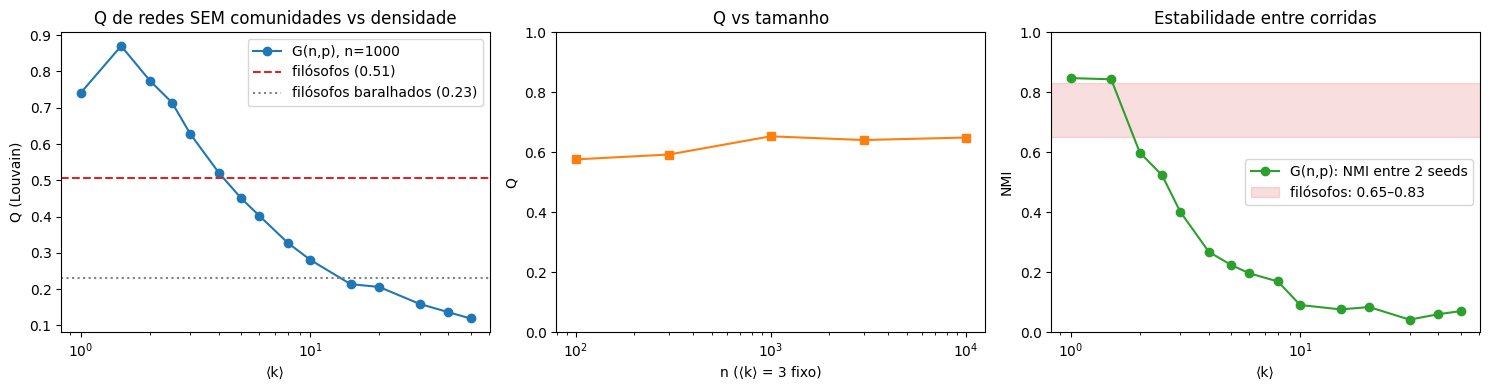

G(n,p) com Q mais perto dos filósofos: ⟨k⟩ = 4.0, Q = 0.521, NMI entre seeds = 0.268


In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
a = rnd[rnd.sweep == "<k>"]; b = rnd[rnd.sweep == "n"]
axes[0].plot(a.k, a.Q, "o-", label="G(n,p), n=1000")
axes[0].axhline(0.506, color="C3", ls="--", label="filósofos (0.51)")
axes[0].axhline(0.23, color="gray", ls=":", label="filósofos baralhados (0.23)")
axes[0].set_xscale("log"); axes[0].set_xlabel("⟨k⟩"); axes[0].set_ylabel("Q (Louvain)"); axes[0].legend()
axes[0].set_title("Q de redes SEM comunidades vs densidade")
axes[1].plot(b.n, b.Q, "s-", color="C1"); axes[1].set_xscale("log"); axes[1].set_ylim(0, 1)
axes[1].set_xlabel("n (⟨k⟩ = 3 fixo)"); axes[1].set_ylabel("Q"); axes[1].set_title("Q vs tamanho")
axes[2].plot(a.k, a.NMI, "o-", color="C2", label="G(n,p): NMI entre 2 seeds")
axes[2].axhspan(0.65, 0.83, color="C3", alpha=0.15, label="filósofos: 0.65–0.83")
axes[2].set_xscale("log"); axes[2].set_ylim(0, 1); axes[2].set_xlabel("⟨k⟩"); axes[2].set_ylabel("NMI")
axes[2].legend(); axes[2].set_title("Estabilidade entre corridas")
plt.tight_layout(); plt.savefig("figs/4.6_random_Q_and_NMI.png", dpi=150); plt.show()

# rede aleatória com Q mais perto de 0.51
match = a.iloc[(a.Q - 0.506).abs().argmin()]
print(f"G(n,p) com Q mais perto dos filósofos: ⟨k⟩ = {match.k}, Q = {match.Q:.3f}, NMI entre seeds = {match.NMI:.3f}")

**Decisão:** usei o **componente gigante** de cada $G(n,p)$. Os nós isolados e os componentes pequenos são
"comunidades grátis" (nenhuma ligação cruza para fora), e com $\langle k\rangle \lesssim 2$ inflacionariam
$Q$ até perto de 1 sem dizer nada sobre o algoritmo. Mesmo só no gigante, os números são altos. (Em
$\langle k\rangle = 1$ o "gigante" tem só 55 nós — estamos no limiar de percolação — por isso esse ponto é pouco fiável.)

**Que parâmetro importa:** a **densidade** $\langle k\rangle$. $Q$ desce de **0.87** ($\langle k\rangle = 1.5$) e
0.78 ($\langle k\rangle = 2$, a página diz ≈ 0.8) até 0.12 para $\langle k\rangle = 50$. Com $\langle k\rangle = 3$
fixo, o tamanho $n$ quase não mexe em $Q$ (0.58 → 0.65 de $n = 100$ a $10\,000$). O máximo que o ruído puro
atinge aqui é **$Q \approx 0.87$** — mais alto do que quase qualquer rede real! (O NMI entre seeds, esse,
cai com $n$: 0.66 → 0.24.)

**Estabilidade:** a rede aleatória cujo $Q$ bate com o dos filósofos (~0.5, com $\langle k\rangle \approx 4$)
($Q = 0.52$) tem NMI entre duas seeds de **0.27**, contra **0.65–0.83** nos filósofos. O *score* não vê a
diferença — ambas dão ~0.5 — mas a *estabilidade* vê: numa rede com grupos reais, corridas diferentes
redescobrem os mesmos grupos; num grafo aleatório, cada corrida inventa as suas fronteiras.
**Q alto + NMI baixo = score sem estrutura.**

*Ressalva:* nas redes mais esparsas ($\langle k\rangle \le 1.5$) o NMI entre seeds volta a ser alto (≈ 0.85) —
o "gigante" é quase uma árvore pequena e os cortes ficam praticamente forçados. Por isso a comparação
justa é à mesma densidade/$Q$ que a rede real, como feito acima ($\langle k\rangle \approx 4$).

In [17]:
# 4.6.5 -- karaté: Q ponderado vs não ponderado, Louvain vs split real
K = nx.karate_club_graph()
real = [{n for n, d in K.nodes(data=True) if d["club"] == "Mr. Hi"},
        {n for n, d in K.nodes(data=True) if d["club"] == "Officer"}]
print(f"tamanhos do split real: {[len(c) for c in real]}")
print(f"Q real, sem pesos (weight=None): {nxc.modularity(K, real, weight=None):.3f}")
print(f"Q real, COM os pesos de Zachary: {nxc.modularity(K, real):.3f}")
PK = nxc.louvain_communities(K, weight=None, seed=0)
print(f"\nLouvain (weight=None): {len(PK)} comunidades, Q = {nxc.modularity(K, PK, weight=None):.3f}")
print(f"NMI(Louvain, split real) = {nmi(labels(PK, list(K)), labels(real, list(K))):.3f}")
for c in PK: print("  ", sorted(c), "-> clube:", Counter(K.nodes[n]['club'] for n in c))

tamanhos do split real: [17, 17]
Q real, sem pesos (weight=None): 0.358
Q real, COM os pesos de Zachary: 0.391

Louvain (weight=None): 4 comunidades, Q = 0.420
NMI(Louvain, split real) = 0.588
   [0, 1, 2, 3, 7, 11, 12, 13, 17, 19, 21] -> clube: Counter({'Mr. Hi': 11})
   [4, 5, 6, 10, 16] -> clube: Counter({'Mr. Hi': 5})
   [23, 24, 25, 27, 28, 31] -> clube: Counter({'Officer': 6})
   [8, 9, 14, 15, 18, 20, 22, 26, 29, 30, 32, 33] -> clube: Counter({'Officer': 11, 'Mr. Hi': 1})


**4.6.5.** Sem pesos: $Q = 0.358$ (o número da página). Com os pesos do Zachary (nº de contextos em que
os dois interagiam): $Q = 0.391$ (mais alto). **Significado:** as duas contas respondem a
perguntas diferentes — a ponderada pergunta "que fração da *intensidade* de interação fica dentro das
facções?" — e as ligações fortes estão, sobretudo, *dentro* das facções, por isso o valor sobe. Não são
comparáveis entre si; só cada uma com o seu próprio nulo.

O Louvain encontra 4 grupos com $Q = 0.420$ — maior do que o split real — mas com NMI de só 0.59
com as facções: cada facção é partida em dois sub-grupos (os 4 grupos são "puros" — só um membro, o 8, fica
do lado "errado"). Mais $Q$, menos acerto sobre *quantos* grupos havia.

### 4.6.6 — O relatório reescrito em três frases honestas

> *"Louvain detected 9 communities with a modularity of 0.50, proving that the history of philosophy divides into nine schools."*

1. **Valor:** O Louvain (não ponderado, componente gigante com 1374 filósofos) encontrou 9 comunidades
   com $Q = 0.51$; outras seeds dão 7–9 comunidades com $Q$ entre 0.49 e 0.51, que concordam com esta com
   NMI de 0.66–0.78.
2. **Comparação:** Redes baralhadas com os mesmos graus dão $Q = 0.22 \pm 0.003$, por isso a estrutura de
   grupos é muito mais forte do que o acaso ($z \approx 100$).
3. **O que estabelece e o que não:** A partição mostra que as ligações entre artigos se concentram em
   grupos que correspondem aproximadamente a tradições (NMI 0.40 com o século); os nomes das "escolas" são
   a nossa leitura dos membros — uma comunidade junta Avicena a Galileu — e não um resultado do algoritmo.

## Exercício 4.7 — Cliques on paper (🧠 learn)

> Draw two triangles, {A, B, C} and {C, D, E}, sharing the node C, plus one extra link A–F.
>
> 1. Any partition of the nodes puts C in one triangle. Compute Q for {A, B, C} · {D, E} · {F} and for {A, B} · {C, D, E} · {F}. Which scores higher? Whichever wins, what does each partition get wrong about C?
> 2. List every 3-clique. With k=3, which of them are adjacent, and what are the k-clique communities? Name the node that is in two communities, the node that is in none, and the link that belongs to no community.
> 3. Add the link B–D. List the 3-cliques again and find the k=3 communities. What happened, and why is this percolation in miniature? What does k=4 give?
> 4. On the philosophers, k=3 puts 1,155 philosophers in one community and k=6 leaves 78% of them out. Explain each in one sentence.

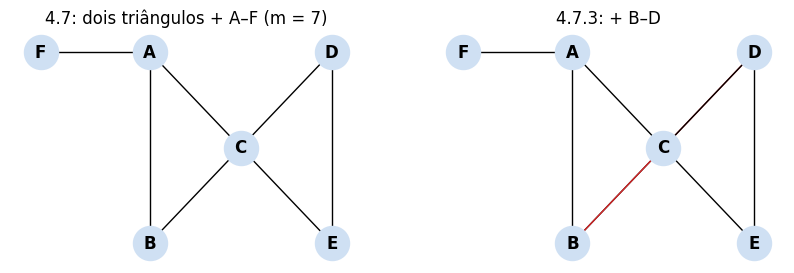

In [18]:
G47 = nx.Graph([("A","B"),("A","C"),("B","C"),("C","D"),("C","E"),("D","E"),("A","F")])
pos47 = {"F":(-1.2,0.8),"A":(0,0.8),"B":(0,-0.8),"C":(1,0),"D":(2,0.8),"E":(2,-0.8)}
G47b = G47.copy(); G47b.add_edge("B", "D")
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, g, t in [(axes[0], G47, "4.7: dois triângulos + A–F (m = 7)"), (axes[1], G47b, "4.7.3: + B–D")]:
    nx.draw_networkx(g, pos47, ax=ax, node_color="#cfe0f3", node_size=600, font_weight="bold",
                     edge_color=["C3" if set(e) == {"B","D"} else "k" for e in g.edges()])
    ax.set_title(t); ax.set_axis_off()
plt.show()

### 4.7.1 — Duas partições

$m = 7$, $2m = 14$, $(2m)^2 = 196$. Graus: $A{=}3,\ B{=}2,\ C{=}4,\ D{=}2,\ E{=}2,\ F{=}1$ (soma 14 ✓).
**Truque — denominador comum 196:** $\ \ell_c/7 = 28\,\ell_c/196$, logo $\ Q = \frac{1}{196}\sum_c (28\,\ell_c - d_c^2)$.

**$\{A,B,C\}\cdot\{D,E\}\cdot\{F\}$:** $\ell = 3, 1, 0$; $d = 3+2+4 = 9,\ 2+2 = 4,\ 1$.
$$
\begin{aligned}
Q &= \tfrac{1}{196}\big[(84 - 81) + (28 - 16) + (0 - 1)\big] \\
  &= \tfrac{3 + 12 - 1}{196} = \tfrac{14}{196} = \tfrac{1}{14} \approx 0.071
\end{aligned}
$$

**$\{A,B\}\cdot\{C,D,E\}\cdot\{F\}$:** $\ell = 1, 3, 0$; $d = 3+2 = 5,\ 4+2+2 = 8,\ 1$.
$$
\begin{aligned}
Q &= \tfrac{1}{196}\big[(28 - 25) + (84 - 64) + (0 - 1)\big] \\
  &= \tfrac{3 + 20 - 1}{196} = \tfrac{22}{196} = \tfrac{11}{98} \approx 0.112
\end{aligned}
$$

**A segunda ganha** (por $8/196 \approx 0.041$): o triângulo $\{A,B,C\}$ tem um grau total mais pesado
(A traz a ligação para F), por isso pôr C lá paga um termo nulo maior ($9^2 = 81$ vs $8^2 = 64$).

**O que cada uma erra sobre C:** C pertence *aos dois* triângulos — tem 2 ligações em cada. A primeira
corta C–D e C–E e diz que C não tem nada a ver com D, E; a segunda corta A–C e B–C e diz o contrário.
Nenhuma partição pode dizer "C está nos dois". (E ambas deixam F sozinho, o que o 4.3.5 mostra ser
sempre subótimo — juntar F a A aumentaria $Q$.)

### 4.7.2 — 3-cliques e comunidades com $k = 3$

3-cliques (triângulos): $\{A,B,C\}$ e $\{C,D,E\}$ — só estes dois.
**Adjacência:** dois 3-cliques são adjacentes se partilham $k - 1 = 2$ nós. $\{A,B,C\} \cap \{C,D,E\} = \{C\}$,
só 1 nó ⇒ **não adjacentes**. Logo há **duas comunidades**: $\{A,B,C\}$ e $\{C,D,E\}$.
- Nó em **duas** comunidades: **C**.
- Nó em **nenhuma**: **F** (não está em nenhum triângulo).
- Ligação em **nenhuma** comunidade: **A–F**.

### 4.7.3 — Acrescentar B–D

B–D fecha um novo triângulo com B–C e C–D: $\{B,C,D\}$. 3-cliques: $\{A,B,C\},\ \{B,C,D\},\ \{C,D,E\}$.
- $\{A,B,C\} \cap \{B,C,D\} = \{B,C\}$ (2 nós) ⇒ adjacentes.
- $\{B,C,D\} \cap \{C,D,E\} = \{C,D\}$ (2 nós) ⇒ adjacentes.

O triângulo "rola" de $\{A,B,C\}$ para $\{B,C,D\}$ para $\{C,D,E\}$ ⇒ **uma só comunidade** $\{A,B,C,D,E\}$
(F continua fora). **Percolação em miniatura:** uma única ligação a mais criou uma ponte de cliques
adjacentes e fundiu as duas comunidades numa — tal como em $G(n,p)$ uma pequena subida da densidade faz
aparecer de repente um componente gigante, aqui um pequeno aumento de triângulos faz as comunidades de
cliques colarem-se todas.
**$k = 4$:** um 4-clique precisaria de 4 nós todos ligados; $\{A,B,C,D\}$ falha A–D, $\{B,C,D,E\}$ falha
B–E ⇒ **não há 4-cliques, logo nenhuma comunidade** (todos os nós ficam de fora).

### 4.7.4 — Os filósofos em $k = 3$ e $k = 6$

- **$k = 3$:** triângulos estão por todo o lado e partilhar um lado (2 nós) é fácil, por isso os triângulos
  percolam por quase toda a rede e colam 1155 filósofos numa comunidade gigante — a transição de percolação.
- **$k = 6$:** para estar numa comunidade é preciso pertencer a um 6-clique (15 ligações entre 6 pessoas),
  o que só acontece em núcleos muito densos de escolas pequenas; 78% dos filósofos não estão em nenhum.

In [19]:
# Verificação do 4.7
for P in [[set("ABC"), set("DE"), {"F"}], [set("AB"), set("CDE"), {"F"}]]:
    print([''.join(sorted(c)) for c in P], "Q =", Q_frac(G47, P), f"= {nxc.modularity(G47, P):.4f}")
for g, t in [(G47, "original"), (G47b, "+ B–D")]:
    cl3 = [sorted(c) for c in nx.enumerate_all_cliques(g) if len(c) == 3]
    for k in [3, 4]:
        comms = [sorted(c) for c in nxc.k_clique_communities(g, k)]
        print(f"{t:9s} 3-cliques={cl3}  k={k}: {comms}")

['ABC', 'DE', 'F'] Q = 1/14 = 0.0714
['AB', 'CDE', 'F'] Q = 11/98 = 0.1122
original  3-cliques=[['A', 'B', 'C'], ['C', 'D', 'E']]  k=3: [['C', 'D', 'E'], ['A', 'B', 'C']]
original  3-cliques=[['A', 'B', 'C'], ['C', 'D', 'E']]  k=4: []
+ B–D     3-cliques=[['A', 'B', 'C'], ['B', 'C', 'D'], ['C', 'D', 'E']]  k=3: [['A', 'B', 'C', 'D', 'E']]
+ B–D     3-cliques=[['A', 'B', 'C'], ['B', 'C', 'D'], ['C', 'D', 'E']]  k=4: []


In [20]:
# 4.7.4 -- tabela da página (k-clique communities nos filósofos)
rows = []
for k in [3, 4, 5, 6]:
    comms = [set(c) for c in nxc.k_clique_communities(GU, k)]
    cover = Counter(n for c in comms for n in c)
    rows.append(dict(k=k, comunidades=len(comms), maior=max(map(len, comms)),
                     filosofos_em_alguma=len(cover), pct=f"{100*len(cover)/len(GU):.0f}%",
                     em_duas_ou_mais=sum(1 for v in cover.values() if v >= 2)))
    if k == 5:
        top = sorted(cover, key=lambda n: -cover[n])[:4]
        print("k=5, mais comunidades:", [(name[n], cover[n]) for n in top])
print(pd.DataFrame(rows).to_string(index=False))

k=5, mais comunidades: [('Aristotle', 6), ('Augustine of Hippo', 5), ('Friedrich Nietzsche', 5), ('Thomas Aquinas', 5)]
 k  comunidades  maior  filosofos_em_alguma pct  em_duas_ou_mais
 3           19   1155                 1189 87%               29
 4           36    817                  909 66%               86
 5           40    467                  555 40%              112
 6           39    171                  304 22%               86


## Exercício 4.8 — Overlap on paper (🧠 learn)

> Use the drawing from exercise 4.7, without the extra link B–D: triangles {A, B, C} and {C, D, E}, plus A–F.
>
> 1. List the seven links. For each pair of links that share a node, say whether they belong to the same context (same triangle) or not, and group the links into link communities by eye. Which node ends up in two communities? Which link is in a community of its own?
> 2. Compare with your k=3 clique communities from 4.7. Where do the two methods agree, and what does the link method say about F that the clique method does not?
> 3. Explain in two sentences why a node in two communities has a less dense neighborhood than a node in one, and what that does to a method that ranks nodes by neighborhood density.
> 4. Name three overlapping communities you belong to and one person who is in exactly one of them. Where would a node partition of your friends put you, and what would it get wrong?

### 4.8.1 — Os sete links e os seus contextos

Links: **A–B, A–C, B–C** (triângulo 1), **C–D, C–E, D–E** (triângulo 2), **A–F**.

Pares de links que partilham um nó:

| nó partilhado | pares | mesmo contexto? |
|---|---|---|
| A | A–B & A–C | sim (triângulo 1) |
| A | A–B & A–F, A–C & A–F | **não** (A–F não está em nenhum triângulo) |
| B | A–B & B–C | sim (triângulo 1) |
| C | A–C & B–C | sim (triângulo 1) |
| C | C–D & C–E | sim (triângulo 2) |
| C | A–C & C–D, A–C & C–E, B–C & C–D, B–C & C–E | **não** (triângulos diferentes) |
| D | C–D & D–E | sim (triângulo 2) |
| E | C–E & D–E | sim (triângulo 2) |

Comunidades de links (por olho): $\{AB, AC, BC\}$, $\{CD, CE, DE\}$, $\{AF\}$.
Cada nó herda as comunidades dos seus links:
- **C** fica em **duas** comunidades (triângulo 1 e triângulo 2);
- (A também fica em duas: triângulo 1 e a comunidade $\{AF\}$ — o "contexto F");
- **A–F** é o link numa comunidade só dele.

Com a similaridade de Jaccard dos vizinhos inclusivos (a do enunciado do 4.9), por exemplo:
$S(AB, AC) = \frac{|N^+(B)\cap N^+(C)|}{|N^+(B)\cup N^+(C)|} = \frac{|\{A,B,C\}|}{|\{A,B,C,D,E\}|} = \frac{3}{5}$,
$S(AC, CD) = \frac{|\{A,B,C,F\}\cap\{C,D,E\}|}{|\{A,B,C,D,E,F\}|} = \frac{1}{6}$,
$S(AB, AF) = \frac{|\{A,B,C\}\cap\{A,F\}|}{|\{A,B,C,F\}|} = \frac{1}{4}$ — os pares "mesmo contexto" são os mais semelhantes,
como o agrupamento por olho supõe (verificado em código abaixo).

### 4.8.2 — Comparação com as $k$-clique communities

**Concordam** nos dois triângulos e em pôr **C nas duas** comunidades. **Diferem em F:** o método de
cliques deixa F (e o link A–F) **sem comunidade**; o método de links dá a F uma comunidade — pequena,
só $\{A, F\}$ — porque todo o link pertence a exatamente uma comunidade de links, logo todo o nó com pelo
menos uma ligação tem pelo menos uma comunidade.

### 4.8.3 — O paradoxo da sobreposição

Os vizinhos de um nó em duas comunidades estão divididos em dois grupos que não se ligam entre si
(os vizinhos de C em $\{A,B\}$ não conhecem os de $\{D,E\}$), por isso a vizinhança dele é *menos* densa
(o clustering de C é $2/6 = 1/3$, enquanto o de B é 1) do que a de um nó que vive num só grupo.
Um método que ordena nós por densidade de vizinhança classifica precisamente os nós de sobreposição —
os mais "comunitários", membros de várias comunidades — como os **menos** comunitários, e tende a
empurrá-los para fronteiras ou para fora.

### 4.8.4 — Pessoal *(esta é para tu escreveres; esqueleto)*

Exemplo de estrutura: **(1)** colegas de Biomedical Engineering na DTU, **(2)** o grupo do projeto de
Social Graphs, **(3)** amigos de Portugal/do Porto. Uma pessoa que só está no (3) — um amigo de infância
no Porto que não conhece ninguém de Copenhaga. Uma partição de nós dos teus amigos pôr-te-ia provavelmente
na comunidade onde tens **mais** ligações (por exemplo, a DTU), e perderia que és a **ponte** entre os
três grupos — exatamente o papel de C: o nó que liga contextos que, sem ti, não se tocam.

In [21]:
# Verificação do 4.8 com a similaridade de links (a mesma função é usada no 4.9)
def link_similarity(G, e1, e2):
    # e1 = (i,k), e2 = (j,k) partilham k; Jaccard das vizinhanças inclusivas de i e j
    k = (set(e1) & set(e2)).pop()
    i = (set(e1) - {k}).pop(); j = (set(e2) - {k}).pop()
    Ni, Nj = set(G[i]) | {i}, set(G[j]) | {j}
    return len(Ni & Nj) / len(Ni | Nj)

E47 = [tuple(sorted(e)) for e in G47.edges()]
for e1, e2 in combinations(E47, 2):
    if set(e1) & set(e2):
        print(f"{'-'.join(e1)} & {'-'.join(e2)}: S = {Fr(link_similarity(G47, e1, e2)).limit_denominator(20)}")
print("\nclustering:", {n: round(c, 3) for n, c in nx.clustering(G47).items()})

A-B & A-C: S = 3/5
A-B & A-F: S = 1/4
A-B & B-C: S = 1/2
A-C & A-F: S = 1/6
A-C & B-C: S = 3/4
A-C & C-D: S = 1/6
A-C & C-E: S = 1/6
B-C & C-D: S = 1/5
B-C & C-E: S = 1/5
C-D & C-E: S = 1
C-D & D-E: S = 3/5
C-E & D-E: S = 3/5

clustering: {'A': 0.333, 'B': 1.0, 'C': 0.333, 'D': 1.0, 'E': 1.0, 'F': 0}


## Exercício 4.9 — Overlap or Infomap on the philosophers (🔬 tool)

> Pick one of the two, run it on the philosophers' giant component, and compare with Louvain.
>
> - **Link communities.** Have your agent implement link clustering from the description above: similarity between links sharing a node as the Jaccard score of the two other endpoints' inclusive neighborhoods [...], then single-linkage hierarchical clustering of the links, cut at the maximum partition density. Report how many communities Aristotle belongs to and name the five largest from their members. Then count the philosophers that belong to two or more communities: are they the hubs, or someone else?
> - **Infomap** [...] report the number of modules and the NMI against your Louvain partition. Which groups do the two methods agree on, and which does one of them split?
> - 🔬 Either way, validate: take five philosophers your method puts in two communities (or moves between methods) and read their Wikipedia pages. Does the overlap or the disagreement correspond to something real about the philosopher? Keep the validation cell; it is the model for your project's AI_METHODS.md.

Fiz **os dois** (link communities como principal, Infomap como comparação curta).

In [22]:
# 4.9 (a) -- link clustering (Ahn, Bagrow & Lehmann 2010), implementado de raiz
def link_communities(G):
    edges_ = [tuple(sorted(e)) for e in G.edges()]
    eidx = {e: i for i, e in enumerate(edges_)}
    Nplus = {n: set(G[n]) | {n} for n in G}
    # 1) similaridade de todos os pares de links que partilham um nó
    pairs = []
    for k in G:
        nb = list(G[k])
        for a, b in combinations(nb, 2):
            s = len(Nplus[a] & Nplus[b]) / len(Nplus[a] | Nplus[b])
            pairs.append((s, eidx[tuple(sorted((a, k)))], eidx[tuple(sorted((b, k)))]))
    pairs.sort(key=lambda x: -x[0])
    M = len(edges_)

    def run(stop_at=None):
        # single linkage com union-find; D atualizado incrementalmente; devolve (melhor D, limiar)
        parent = list(range(M))
        mc = [1] * M
        nodes_c = [set(e) for e in edges_]
        def find(x):
            while parent[x] != x:
                parent[x] = parent[parent[x]]; x = parent[x]
            return x
        def dterm(m, n):
            return 0.0 if n <= 2 else m * (m - (n - 1)) / ((n - 2) * (n - 1))
        Dsum = 0.0                        # todos os clusters iniciais têm n=2 -> termo 0
        best = (0.0, 1.0)
        i = 0
        while i < len(pairs):
            s = pairs[i][0]
            if stop_at is not None and s < stop_at: break
            while i < len(pairs) and pairs[i][0] == s:       # processa um nível inteiro de similaridade
                _, x, y = pairs[i]; rx, ry = find(x), find(y)
                if rx != ry:
                    Dsum -= dterm(mc[rx], len(nodes_c[rx])) + dterm(mc[ry], len(nodes_c[ry]))
                    if len(nodes_c[rx]) < len(nodes_c[ry]): rx, ry = ry, rx
                    parent[ry] = rx; mc[rx] += mc[ry]; nodes_c[rx] |= nodes_c[ry]; nodes_c[ry] = set()
                    Dsum += dterm(mc[rx], len(nodes_c[rx]))
                i += 1
            D = 2 * Dsum / M
            if D > best[0]: best = (D, s)
        groups = defaultdict(list)
        for e in range(M): groups[find(e)].append(edges_[e])
        return best, list(groups.values())

    (Dmax, s_star), _ = run()
    _, comms = run(stop_at=s_star)    # repete até ao nível do máximo e corta aí
    return Dmax, s_star, comms, len(pairs)

# teste na rede de brincar do 4.7/4.8
D_toy, s_toy, comms_toy, _ = link_communities(G47)
print("toy:", f"D = {D_toy:.3f}", [sorted('-'.join(e) for e in c) for c in comms_toy])

t0 = time.time()
Dmax, s_star, LC, npairs = link_communities(GU)
print(f"\nfilósofos: {npairs} pares de links, D máx = {Dmax:.3f} no limiar S = {s_star:.3f} ({time.time()-t0:.1f} s)")
print(f"{len(LC)} comunidades de links; com ≥3 links: {sum(1 for c in LC if len(c) >= 3)}")

toy: D = 0.857 [['A-B', 'A-C', 'B-C'], ['A-F'], ['C-D', 'C-E', 'D-E']]

filósofos: 362270 pares de links, D máx = 0.054 no limiar S = 0.236 (2.1 s)
4729 comunidades de links; com ≥3 links: 444


Validação contra a página: nas *Goodies* ("adaptive cut"), o corte a uma só altura nos filósofos dá
**$D = 0.054$** e **444 comunidades com 3 ou mais links** — os mesmos números que a implementação acima.

In [23]:
# comunidades de nós herdadas dos links
node_comms = defaultdict(set)
LCn = [set(n for e in c for n in e) for c in LC]
for ci, c in enumerate(LC):
    for u, v in c:
        node_comms[u].add(ci); node_comms[v].add(ci)
big = {ci for ci, c in enumerate(LC) if len(c) >= 3}     # comunidades "a sério"
A = "Aristotle"
print(f"Aristóteles: {len(node_comms[A])} comunidades (todas), {len(node_comms[A] & big)} com ≥3 links; grau {deg[A]}")

print("\nAs cinco maiores comunidades de links:")
for ci in sorted(range(len(LC)), key=lambda c: -len(LC[c]))[:5]:
    memb = LCn[ci]
    print(f"  {len(LC[ci]):4d} links, {len(memb):3d} nós | " + ", ".join(name_of(memb, 8)))

Aristóteles: 106 comunidades (todas), 23 com ≥3 links; grau 300

As cinco maiores comunidades de links:
   566 links, 113 nós | Cicero, Diogenes Laertius, Heraclitus, Pythagoras, Plutarch, Simplicius of Cilicia, Origen, Democritus
   323 links, 201 nós | Aristotle, Plato, Cicero, Diogenes Laertius, Heraclitus, Socrates, Pythagoras, Plutarch
   166 links,  73 nós | Avicenna, Simplicius of Cilicia, Averroes, Maimonides, Proclus, Al-Ghazali, Al-Farabi, John Philoponus
   134 links,  46 nós | Zhu Xi, Mao Zedong, Mencius, Zichan, Xunzi (philosopher), Liang Qichao, Shen Dao, Hu Shih
   118 links,  62 nós | Immanuel Kant, Georg Wilhelm Friedrich Hegel, Friedrich Wilhelm Joseph Schelling, Wilhelm Wundt, Johann Gottlieb Fichte, Hermann Lotze, Rudolf Steiner, Friedrich Schiller


In [24]:
from scipy.stats import spearmanr
n_all = {n: len(node_comms[n]) for n in GU}
n_big = {n: len(node_comms[n] & big) for n in GU}
multi_all = [n for n in GU if n_all[n] >= 2]
multi_big = [n for n in GU if n_big[n] >= 2]
print(f"filósofos em ≥2 comunidades (todas):     {len(multi_all)} de {len(GU)}")
print(f"filósofos em ≥2 comunidades (≥3 links):  {len(multi_big)}")
rho = spearmanr([deg[n] for n in GU], [n_all[n] for n in GU]).correlation
print(f"Spearman(grau, nº de comunidades) = {rho:.2f}")
print(f"grau médio: em ≥2 comunidades (≥3 links) = {np.mean([deg[n] for n in multi_big]):.1f}  |  resto = "
      f"{np.mean([deg[n] for n in GU if n_big[n] < 2]):.1f}")

# comunidades por link: quem é "ponte" relativamente ao seu grau (grau ≥ 20)
ratio = sorted((n for n in GU if deg[n] >= 20), key=lambda n: -n_big[n] / deg[n])
print("\nmais comunidades (≥3 links) por ligação, grau ≥ 20:")
for n in ratio[:8]: print(f"  {name[n]:30s} {n_big[n]:3d} comunidades / {deg[n]:3d} ligações")
print("menos:")
for n in ratio[-5:]: print(f"  {name[n]:30s} {n_big[n]:3d} comunidades / {deg[n]:3d} ligações")

filósofos em ≥2 comunidades (todas):     1241 de 1374
filósofos em ≥2 comunidades (≥3 links):  693
Spearman(grau, nº de comunidades) = 0.92
grau médio: em ≥2 comunidades (≥3 links) = 19.7  |  resto = 6.8

mais comunidades (≥3 links) por ligação, grau ≥ 20:
  John Peckham                     9 comunidades /  20 ligações
  Johannes Kepler                 12 comunidades /  28 ligações
  Benjamin Franklin               10 comunidades /  25 ligações
  Thomas Reid                     13 comunidades /  34 ligações
  Dugald Stewart                   9 comunidades /  25 ligações
  Kiyoshi Miki                     7 comunidades /  20 ligações
  Ibn al-Haytham                   9 comunidades /  26 ligações
  Samuel von Pufendorf             7 comunidades /  21 ligações
menos:
  Friedrich Adolf Trendelenburg    0 comunidades /  20 ligações
  Joseph de Maistre                0 comunidades /  25 ligações
  Julius Evola                     0 comunidades /  26 ligações
  Peter Kropotkin               

**As cinco maiores:** (1) 566 links — a Antiguidade *através das fontes* (Cícero, Diógenes Laércio,
Plutarco, Simplício com Heraclito, Pitágoras, Demócrito): a doxografia; (2) 323 links — o núcleo clássico
(Aristóteles, Platão, Sócrates); (3) 166 links — a tradição de comentário de Aristóteles, islâmica e
neoplatónica (Avicena, Averróis, Maimónides, Simplício, Proclo, Filopono); (4) 134 links — filosofia chinesa
(Zhu Xi, Mêncio, Xunzi); (5) 118 links — idealismo e psicologia alemã (Kant, Hegel, Schelling, Fichte, Wundt,
Lotze).

**Resultado.** Aristóteles está em **106** comunidades de links (23 com ≥3 links) — o hub máximo participa
em muitos contextos. 1241 dos 1374 filósofos estão em ≥2 comunidades (693 contando só as de ≥3 links). Os que estão em duas ou mais comunidades **são, sobretudo, os hubs**: o número de
comunidades acompanha o grau (Spearman 0.92; as *Goodies* dão 0.83 para o *adaptive cut*), e o
grau médio dos "sobrepostos" é ~3× o dos outros (19.7 vs 6.8). Isto é em parte mecânico — mais links, mais
oportunidades de cair em comunidades diferentes — por isso o número mais revelador é **comunidades por
ligação**: um filósofo com muitas comunidades para relativamente poucas ligações é uma ponte entre
contextos, enquanto um hub citado sempre "do mesmo lado" fica com poucas comunidades para muitas ligações.
Aqui aparecem **Kepler** (12 comunidades para 28 ligações — o mesmo exemplo das *Goodies*), John Peckham,
Benjamin Franklin, Thomas Reid e Ibn al-Haytham: polímatas entre ciência, teologia e filosofia. No extremo
oposto, Kropotkin, Carl Schmitt ou Julius Evola têm 20+ ligações e **nenhuma** comunidade de ≥3 links —
ligações dispersas que não formam contexto nenhum (a fraqueza dos métodos de sobreposição em zonas esparsas).

In [25]:
# 4.9 (b) -- Infomap, comparado com o Louvain
from infomap import Infomap
im = Infomap("--two-level --silent --seed 42")
idx = {n: i for i, n in enumerate(ORDER)}
for u, v in GU.edges(): im.add_link(idx[u], idx[v])
im.run()
mod = {ORDER[nd.node_id]: nd.module_id for nd in im.nodes}
mod_members = defaultdict(set)
for n, c in mod.items(): mod_members[c].add(n)
PI = sorted(mod_members.values(), key=len, reverse=True)
print(f"Infomap: {len(PI)} módulos, tamanhos maiores: {[len(c) for c in PI[:12]]}")
print(f"Q da partição Infomap = {nxc.modularity(GU, PI):.3f}   |  NMI(Infomap, Louvain) = {nmi(labels(PI), labels(P0)):.3f}")

# tabela de contingência: para cada comunidade Louvain, como é que o Infomap a reparte
print("\nComo o Infomap reparte cada comunidade do Louvain (frações ≥ 10%):")
for c in P0:
    cnt = Counter(mod[n] for n in c)
    parts = [(v, name_of(mod_members[m_id], 1)[0]) for m_id, v in cnt.most_common() if v / len(c) >= 0.10]
    print(f"  {name_of(c, 1)[0]:25s} ({len(c):3d}) -> " + ", ".join(f"{v} em [{lead}]" for v, lead in parts))

ModuleNotFoundError: No module named 'infomap'

**Infomap vs Louvain.** O Infomap encontra **37 módulos** ($Q$ da sua partição = 0.47, menor — não é isso
que otimiza) e NMI = **0.68** com o Louvain, tanto como entre duas seeds do próprio Louvain.
- **Concordam:** Antiguidade (193 de 214 no mesmo módulo), cristãos/escolásticos (177/213), chineses (75/83).
- **O Infomap parte:** os alemães em Kant / Nietzsche / Marx; o grupo de Russell em quatro (Russell,
  Bergson, Sidgwick, e uma parte que vai para Kant); a filosofia indiana em Vedanta (Shankara) / budismo /
  Dvaita (Madhva); e a islâmica em islâmicos vs judeus (Maimónides) — escolas reais, que o Louvain funde.
- **O Infomap funde:** 185 dos 220 do grupo de Descartes caem no módulo de Kant — para o caminhante
  aleatório, o início da modernidade e o idealismo alemão são um só "fluxo".

In [ ]:
# 🔬 Validação: cinco filósofos com sobreposição, lidos contra a descrição da Wikipédia (coluna description)
cands = [n for n in ["Averroes", "Boethius", "Johannes_Kepler", "Gottfried_Wilhelm_Leibniz", "Pythagoras",
                     "Nicolaus_Copernicus", "Isaac_Newton", "Moses_Mendelssohn"] if n in GU][:5]
for n in cands:
    lc = sorted(node_comms[n] & big, key=lambda c: -len(LC[c]))[:4]
    ctx = ["{" + ", ".join(name_of(LCn[c] - {n}, 3)) + "}" for c in lc]
    print(f"■ {name[n]} — grau {deg[n]}, {n_big[n]} comunidades (≥3 links); Louvain: [{name_of(next(c for c in P0 if n in c),1)[0]}]")
    print(f"   contextos maiores: {'; '.join(ctx)}")
    print(f"   Wikipédia: {desc[n][:220]}\n")

■ Averroes — grau 55, 10 comunidades (≥3 links); Louvain: [Avicenna]
   contextos maiores: {Aristotle, Plato, Cicero}; {Avicenna, Simplicius of Cilicia, Maimonides}; {Avicenna, Roger Bacon, Al-Ghazali}; {Avicenna, Simplicius of Cilicia, Porphyry of Tyre}
   Wikipédia: Ibn Rushd, Latinized as Averroes, was an Andalusian polymath and jurist who was proficient in a variety of intellectual fields, including philosophy, theology, medicine, astronomy, physics, psychology, mathematics, neuro

■ Boethius — grau 47, 3 comunidades (≥3 links); Louvain: [Thomas Aquinas]
   contextos maiores: {William of Conches, Gilbert de la Porrée, Adelard of Bath}; {Jean Buridan, Thomas Bradwardine, Albert of Saxony (philosopher)}; {Proclus, Iamblichus, Ammonius Hermiae}
   Wikipédia: Anicius Manlius Severinus Boethius, commonly known simply as Boethius, was a Roman senator, consul, magister officiorum, polymath, historian, and philosopher of the Early Middle Ages.

■ Johannes Kepler — grau 28, 12 comunidades (

**Leitura da validação.** Para cada um, os contextos em que o método o põe correspondem a coisas reais da
biografia: **Averróis** com Aristóteles/Platão **e** com Avicena, Maimónides e Roger Bacon (foi "o
Comentador" de Aristóteles, lido pelos latinos); **Boécio** com a escola de Chartres, com os lógicos do
séc. XIV (Buridan, Bradwardine) **e** com os neoplatónicos (Proclo, Jâmblico) — traduziu a lógica de
Aristóteles e foi manual de toda a Idade Média; **Kepler** com Aristóteles/Platão, com a astronomia árabe
(Avicena, Averróis), com Galileu/Copérnico e com Ptolomeu/al-Kindi — astrónomo, matemático e filósofo
natural; **Leibniz** com os cartesianos (Malebranche, Bayle), com Galileu/Arquimedes, com os empiristas
(Locke, Hume) e com a psicologia alemã (Wundt, Lotze); **Pitágoras** com os pré-socráticos e os doxógrafos
(Diógenes Laércio, Plutarco) e com os neoplatónicos (Porfírio escreveu uma *Vida de Pitágoras*). A sobreposição é **informação**, não ruído — é o que uma partição de nós deita
fora. *Nota honesta:* aqui li a descrição de uma linha que vem no ficheiro de nós (tirada da Wikipédia),
não a página completa; para o `AI_METHODS.md` do projeto, a validação deve citar a página lida e a data.

## Exercício 4.10 — Weights by hand (🧠 learn)

> Take the network from exercise 4.1 and give the links weights: A–B 3, A–C 1, B–C 4, C–D 1, D–E 2, D–F 5, E–F 2, F–G 1.
>
> 1. Compute the strength of every node. Which node has the highest degree, which the highest strength, and are they the same?
> 2. Find the shortest path from A to E by hops, then by weighted length with 1/w as the link length. Are they the same path? Say in one sentence what the weighted path "prefers."
> 3. Compute the weighted modularity of the partition {A, B, C} · {D, E, F, G}: weights in place of link counts, strengths in place of degrees, total weight in place of m. Is it higher or lower than the unweighted Q from 4.3, and why?
> 4. A report says "the weighted modularity (0.55) is higher than the unweighted (0.50), so weights reveal stronger community structure." What is wrong with the sentence?

### 4.10.1 — Força $s_i = \sum_j w_{ij}$

$$
\begin{aligned}
s_A &= w_{AB} + w_{AC} = 3 + 1 = 4 \\
s_B &= w_{AB} + w_{BC} = 3 + 4 = 7 \\
s_C &= w_{AC} + w_{BC} + w_{CD} = 1 + 4 + 1 = 6 \\
s_D &= w_{CD} + w_{DE} + w_{DF} = 1 + 2 + 5 = 8 \\
s_E &= w_{DE} + w_{EF} = 2 + 2 = 4 \\
s_F &= w_{DF} + w_{EF} + w_{FG} = 5 + 2 + 1 = 8 \\
s_G &= w_{FG} = 1
\end{aligned}
$$
Verificação: $\sum_i s_i = 38 = 2W$ com $W = 3+1+4+1+2+5+2+1 = 19$ ✓.

**Maior grau:** C, D e F (empate, $k = 3$). **Maior força:** D e F ($s = 8$). Não coincidem totalmente:
C tem grau máximo mas força só 6 — duas das suas três ligações são fracas (A–C e C–D, peso 1); B tem só
grau 2 mas força 7, maior que a de C.

### 4.10.2 — Caminho mais curto de A a E

**Por saltos:** $A \to C \to D \to E$ (3 saltos; qualquer caminho tem de passar por C–D).

**Pesado, comprimento $1/w$** — **truque: ligação forte = curta**. Candidatos:
$$
\begin{aligned}
A\!-\!C\!-\!D\!-\!E &: \tfrac{1}{1} + \tfrac{1}{1} + \tfrac{1}{2} = 2.5 \\
A\!-\!B\!-\!C\!-\!D\!-\!E &: \tfrac{1}{3} + \tfrac{1}{4} + \tfrac{1}{1} + \tfrac{1}{2} = \tfrac{4 + 3 + 12 + 6}{12} = \tfrac{25}{12} \approx 2.083 \\
A\!-\!C\!-\!D\!-\!F\!-\!E &: 1 + 1 + \tfrac{1}{5} + \tfrac{1}{2} = 2.7 \\
A\!-\!B\!-\!C\!-\!D\!-\!F\!-\!E &: \tfrac{1}{3} + \tfrac{1}{4} + 1 + \tfrac{1}{5} + \tfrac{1}{2} = \tfrac{137}{60} \approx 2.283
\end{aligned}
$$
O mais curto pesado é **$A \to B \to C \to D \to E$** ($25/12$), com 4 saltos — **não** é o mesmo caminho.
O caminho pesado **prefere ligações fortes**, mesmo que isso custe um desvio (A–B–C, pesos 3 e 4, "sai
mais barato" do que o atalho fraco A–C, peso 1).

### 4.10.3 — Modularidade pesada de $\{A,B,C\}\cdot\{D,E,F,G\}$

$$
Q_w = \sum_c \left[\frac{W_c}{W} - \left(\frac{S_c}{2W}\right)^2\right],\qquad W = 19,\ 2W = 38,\ (2W)^2 = 1444
$$
- $\{A,B,C\}$: peso interno $W_c = 3 + 1 + 4 = 8$; força $S_c = 4 + 7 + 6 = 17$.
- $\{D,E,F,G\}$: $W_c = 2 + 5 + 2 + 1 = 10$; $S_c = 8 + 4 + 8 + 1 = 21$. (Verificação: $17 + 21 = 38$ ✓; $8 + 10 + 1_{(C\text{–}D)} = 19$ ✓.)

**Truque — denominador comum 1444:** $\ W_c/19 = 76\,W_c/1444$.
$$
\begin{aligned}
Q_w &= \frac{1}{1444}\Big[(76\cdot 8 - 17^2) + (76\cdot 10 - 21^2)\Big] \\
    &= \frac{1}{1444}\Big[(608 - 289) + (760 - 441)\Big] \\
    &= \frac{319 + 319}{1444} = \frac{638}{1444} = \frac{319}{722} \approx 0.442
\end{aligned}
$$
**Mais alto** do que o não pesado ($47/128 \approx 0.367$). Porquê: a única ligação que cruza, C–D, tem
peso 1 — no caso não pesado é $1/8 = 12.5\%$ das ligações a cruzar; no pesado é $1/19 \approx 5.3\%$ do
peso. As ligações fortes estão dentro dos grupos.

### 4.10.4 — "0.55 > 0.50, logo os pesos revelam estrutura mais forte"

Os dois números respondem a **perguntas diferentes** (fração de *ligações* vs fração de *peso* dentro dos
grupos, cada uma com o seu próprio nulo) e **não são comparáveis**. Além disso, o valor pesado tem um
"teto" naturalmente mais alto, porque as ligações fortes concentram-se dentro dos grupos quase por
definição (duas pessoas próximas ligam-se muitas vezes). Para dizer algo, cada valor tem de ser comparado
com o **seu** nulo (baralhamento pesado vs não pesado) — por exemplo, via $z$-scores — e a frase também
ignora a estabilidade (NMI entre corridas).

In [ ]:
# Verificação do 4.10
W41 = {("A","B"):3, ("A","C"):1, ("B","C"):4, ("C","D"):1, ("D","E"):2, ("D","F"):5, ("E","F"):2, ("F","G"):1}
G410 = nx.Graph(); [G410.add_edge(u, v, weight=w, length=1/w) for (u, v), w in W41.items()]
print("força:", dict(G410.degree(weight="weight")), "| grau:", dict(G410.degree()))
print("A->E por saltos:", nx.shortest_path(G410, "A", "E"))
p = nx.dijkstra_path(G410, "A", "E", weight="length")
print("A->E pesado (1/w):", p, "comprimento =", Fr(nx.dijkstra_path_length(G410, "A", "E", weight="length")).limit_denominator(100))
P = [set("ABC"), set("DEFG")]
print(f"Q pesado = {nxc.modularity(G410, P, weight='weight'):.4f} (319/722 = {319/722:.4f}) | Q não pesado = {nxc.modularity(G410, P, weight=None):.4f}")

força: {'A': 4, 'B': 7, 'C': 6, 'D': 8, 'E': 4, 'F': 8, 'G': 1} | grau: {'A': 2, 'B': 2, 'C': 3, 'D': 3, 'E': 2, 'F': 3, 'G': 1}
A->E por saltos: ['A', 'C', 'D', 'E']
A->E pesado (1/w): ['A', 'B', 'C', 'D', 'E'] comprimento = 25/12
Q pesado = 0.4418 (319/722 = 0.4418) | Q não pesado = 0.3672


## Exercício 4.11 — The backbone, and the figure (🔬 tool)

> This figure is the rehearsal for Project B's data story.
>
> 1. Load the weighted network, sum both directions, and compute strength for every philosopher. Plot strength against degree, log axes, and label Diogenes Laertius and the two or three other philosophers farthest from the diagonal.
> 2. Implement the disparity filter from the formula above (no package, no backboning library): for each link, the significance at both ends, keep if either is below α. Reproduce this page's table for α ∈ {0.05, 0.1, 0.2, 0.3, 0.5} and the w ≥ 2, 3, 4 thresholds (3,240 / 1,572 / 785 links). Validate against the explorable's readout at α=0.2.
> 3. Draw the α=0.2 backbone following the five rules: force layout of the backbone only, nodes colored by Louvain community (computed on the full unweighted network) with a named legend, sized by strength, the ten highest-strength philosophers labeled, and a caption that states the filter, the parameter, and what was removed.
> 4. 🔬 Draw the same figure at α=0.1 and 0.3. Write three sentences on what the reader would conclude from each and which one you would put in a paper, and why.

pesos: 1–24, 5899 de 9139 com peso 1
Spearman(força, grau) = 0.96
Aristotle          força 521 (#1), grau 300 (#1)
Diogenes Laertius  força 230 (#5), grau 91 (#15)
mais acima da diagonal: [('Diogenes Laertius', 91, 230, 2.53), ('Madhvacharya', 18, 67, 3.72), ('John Adams', 17, 53, 3.12), ('Mary Wollstonecraft', 15, 46, 3.07)]


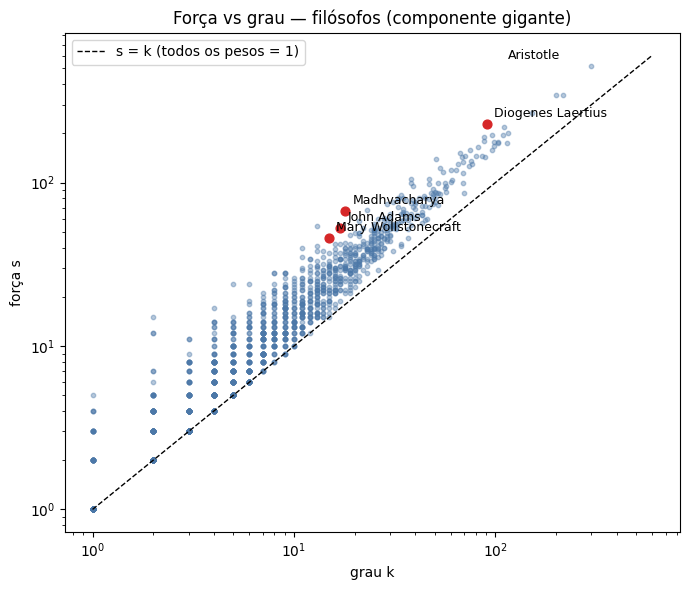

In [ ]:
# 4.11.1 -- força vs grau
strength = dict(giant.degree(weight="weight"))
kdeg = dict(giant.degree())
print(f"pesos: {min(d['weight'] for *_, d in giant.edges(data=True))}–{max(d['weight'] for *_, d in giant.edges(data=True))}, "
      f"{sum(1 for *_, d in giant.edges(data=True) if d['weight'] == 1)} de {giant.number_of_edges()} com peso 1")
from scipy.stats import spearmanr
print(f"Spearman(força, grau) = {spearmanr([strength[n] for n in giant], [kdeg[n] for n in giant]).correlation:.2f}")
rk_s = {n: i+1 for i, n in enumerate(sorted(giant, key=lambda n: -strength[n]))}
rk_k = {n: i+1 for i, n in enumerate(sorted(giant, key=lambda n: -kdeg[n]))}
for n in ["Aristotle", "Diogenes_Laertius"]:
    print(f"{name[n]:18s} força {strength[n]} (#{rk_s[n]}), grau {kdeg[n]} (#{rk_k[n]})")

# "longe da diagonal" = maior s/k, entre filósofos com grau ≥ 15 (senão ganham folhas com uma ligação forte)
far = sorted((n for n in giant if kdeg[n] >= 15), key=lambda n: -strength[n] / kdeg[n])[:4]
if "Diogenes_Laertius" not in far: far = ["Diogenes_Laertius"] + far[:3]
print("mais acima da diagonal:", [(name[n], kdeg[n], strength[n], round(strength[n]/kdeg[n], 2)) for n in far])

fig, ax = plt.subplots(figsize=(7, 6))
xs = np.array([kdeg[n] for n in giant]); ys = np.array([strength[n] for n in giant])
ax.scatter(xs, ys, s=10, alpha=0.4, color="#4c78a8")
lim = [1, 600]; ax.plot(lim, lim, "k--", lw=1, label="s = k (todos os pesos = 1)")
for n in far:
    ax.scatter(kdeg[n], strength[n], s=40, color="C3")
    ax.annotate(name[n], (kdeg[n], strength[n]), xytext=(5, 5), textcoords="offset points", fontsize=9)
ax.annotate("Aristotle", (kdeg["Aristotle"], strength["Aristotle"]), xytext=(-60, 5), textcoords="offset points", fontsize=9)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("grau k"); ax.set_ylabel("força s")
ax.set_title("Força vs grau — filósofos (componente gigante)"); ax.legend()
plt.tight_layout(); plt.savefig("figs/4.11_strength_vs_degree.png", dpi=150); plt.show()

**4.11.1.** Força e grau ordenam os filósofos quase da mesma forma (Spearman ≈ 0.96, como na página);
Aristóteles lidera ambos (força 521, grau 300). As exceções são as interessantes: **Diógenes Laércio** é
só o 15º em grau (91) mas o 5º em força (230) — as *Vidas dos Filósofos Ilustres* são a fonte citada
repetidamente nos artigos de quase todos os antigos. Entre filósofos com grau ≥ 15, os mais acima da
diagonal são **Madhvacharya** (s/k = 3.7: os artigos dos seus sucessores na escola Dvaita — Vyasatirtha, Jayatirtha,
Narayana Panditacharya — citam-no vezes sem conta), **John Adams** (3.1: a ligação Adams–Jefferson tem peso 22) e **Mary Wollstonecraft** (3.1: peso 13 com William Godwin, 7 com Mary Hays) — tudo relações "enredadas" em que um artigo cita o outro muitas vezes.

In [ ]:
# 4.11.2 -- disparity filter escrito de raiz
def disparity_backbone(G, alpha, weight="weight"):
    s = dict(G.degree(weight=weight)); k = dict(G.degree())
    def signif(i, w):
        # probabilidade, sob o nulo "força de i espalhada uniformemente pelas k_i ligações",
        # de uma ligação ter uma fração ≥ p_ij = w/s_i :  (1 - p_ij)^(k_i - 1)
        return 1.0 if k[i] == 1 else (1 - w / s[i]) ** (k[i] - 1)
    B = nx.Graph()
    for u, v, d in G.edges(data=True):
        w = d[weight]
        if signif(u, w) < alpha or signif(v, w) < alpha:
            B.add_edge(u, v, **d)
    return B

# exemplo à mão da página: Moses of Narbonne–Aristóteles, peso 2
mn = "Moses_of_Narbonne"
print(f"Moses of Narbonne: k={kdeg[mn]}, s={strength[mn]} -> (1-2/{strength[mn]})^{kdeg[mn]-1} = {(1-2/strength[mn])**(kdeg[mn]-1):.3f}")
print(f"Aristóteles: (1-2/521)^299 = {(1-2/521)**299:.3f};  limiar p para α=0.2: 1-0.2^(1/299) = {1-0.2**(1/299):.4%}\n")

rows = []
for a in [0.05, 0.1, 0.2, 0.3, 0.5]:
    B = disparity_backbone(giant, a)
    rows.append(dict(filtro=f"disparity α={a}", links=B.number_of_edges(),
                     pct=f"{100*B.number_of_edges()/giant.number_of_edges():.0f}%",
                     filosofos_com_link=B.number_of_nodes(),
                     componente_gigante=len(max(nx.connected_components(B), key=len))))
for th in [2, 3, 4]:
    B = nx.Graph([(u, v) for u, v, d in giant.edges(data=True) if d["weight"] >= th])
    rows.append(dict(filtro=f"threshold w≥{th}", links=B.number_of_edges(),
                     pct=f"{100*B.number_of_edges()/giant.number_of_edges():.0f}%",
                     filosofos_com_link=B.number_of_nodes(),
                     componente_gigante=len(max(nx.connected_components(B), key=len))))
print(pd.DataFrame(rows).to_string(index=False))

Moses of Narbonne: k=10, s=11 -> (1-2/11)^9 = 0.164
Aristóteles: (1-2/521)^299 = 0.317;  limiar p para α=0.2: 1-0.2^(1/299) = 0.5368%

          filtro  links pct  filosofos_com_link  componente_gigante
disparity α=0.05    292  3%                 348                 116
 disparity α=0.1    649  7%                 607                 419
 disparity α=0.2   1540 17%                 950                 816
 disparity α=0.3   2549 28%                1111                1052
 disparity α=0.5   5641 62%                1284                1270
   threshold w≥2   3240 35%                1140                1091
   threshold w≥3   1572 17%                 863                 747
   threshold w≥4    785  9%                 619                 463


In [ ]:
# Validação α = 0.2 vs w ≥ 3 (números do explorable)
B02 = disparity_backbone(giant, 0.2)
T3 = nx.Graph([(u, v, d) for u, v, d in giant.edges(data=True) if d["weight"] >= 3])
only_df = set(B02) - set(T3)
print(f"α=0.2: {B02.number_of_edges()} links, {B02.number_of_nodes()} filósofos | w≥3: {T3.number_of_edges()} links, {T3.number_of_nodes()} filósofos")
print(f"ligados pelo filtro mas largados pelo limiar: {len(only_df)}; "
      f"a ligação mais forte de todos eles é 2: {all(max(d['weight'] for d in giant[n].values()) == 2 for n in only_df)}")
dropped = [d["weight"] for u, v, d in giant.edges(data=True) if not B02.has_edge(u, v)]
print(f"ligação mais forte descartada a α=0.2: peso {max(dropped)}")
print(f"Aristóteles–Newton (peso {giant['Aristotle']['Isaac_Newton']['weight']}) no backbone α=0.2? {B02.has_edge('Aristotle','Isaac_Newton')}")

α=0.2: 1540 links, 950 filósofos | w≥3: 1572 links, 863 filósofos
ligados pelo filtro mas largados pelo limiar: 112; a ligação mais forte de todos eles é 2: True
ligação mais forte descartada a α=0.2: peso 6
Aristóteles–Newton (peso 2) no backbone α=0.2? False


**4.11.2.** A tabela bate **exatamente** com a da página (292/649/1540/2549/5641 links; 348/607/950/1111/1284
filósofos; gigantes 116/419/816/1052/1270) e com os limiares (3240/1572/785). A validação com o readout do
explorable a $\alpha = 0.2$ também: 1540 links, 950 filósofos, gigante 816; 112 filósofos ligados pelo filtro
e largados pelo limiar $w \ge 3$, todos com a ligação mais forte igual a 2; a ligação mais forte descartada
tem peso 6. (A ligação Aristóteles–Newton, peso 2, que o explorable mostra a desaparecer com $w \ge 3$,
também não passa no filtro: 2/521 é pouco para Aristóteles e, com o grau de Newton, também não é
significativa do lado dele.)

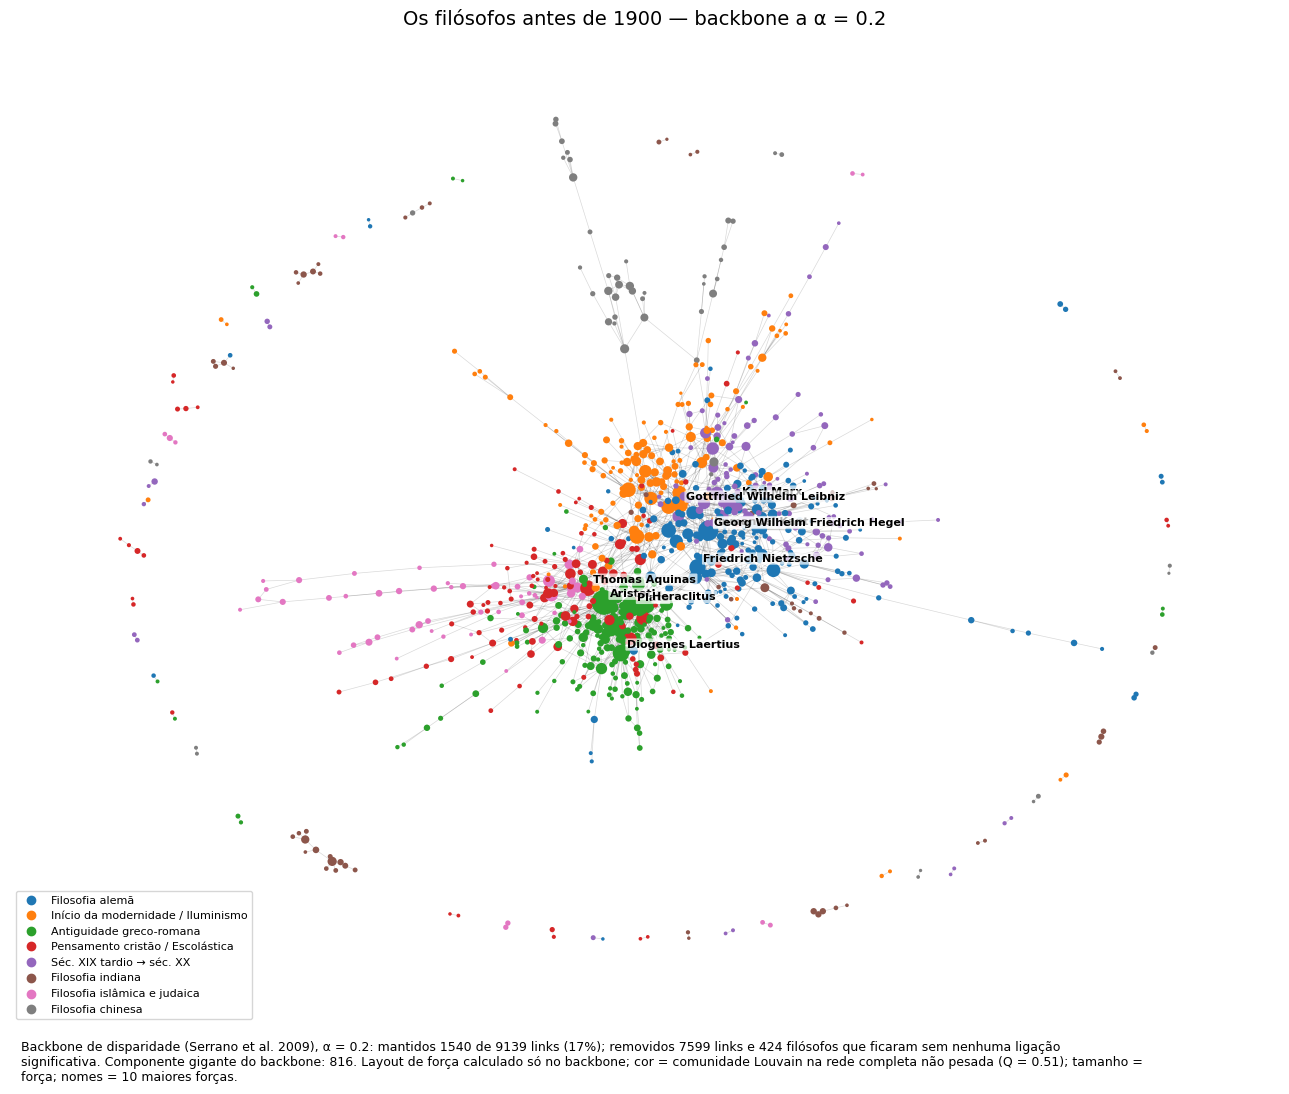

Backbone de disparidade (Serrano et al. 2009), α = 0.2: mantidos 1540 de 9139 links (17%); removidos 7599 links e 424 filósofos que ficaram sem nenhuma ligação significativa. Componente gigante do backbone: 816. Layout de força calculado só no backbone; cor = comunidade Louvain na rede completa não pesada (Q = 0.51); tamanho = força; nomes = 10 maiores forças.


In [ ]:
# 4.11.3 -- a figura, com as cinco regras
# nomes das comunidades Louvain (seed 0, rede completa não pesada) pelo membro de maior grau
LABEL = {"Immanuel Kant": "Filosofia alemã", "René Descartes": "Início da modernidade / Iluminismo",
         "Aristotle": "Antiguidade greco-romana", "Thomas Aquinas": "Pensamento cristão / Escolástica",
         "Bertrand Russell": "Séc. XIX tardio → séc. XX", "The Buddha": "Filosofia indiana",
         "Avicenna": "Filosofia islâmica e judaica", "Confucius": "Filosofia chinesa"}
comm_of = {n: i for i, c in enumerate(P0) for n in c}
comm_name = {i: LABEL.get(name_of(c, 1)[0], f"grupo de {name_of(c, 1)[0]}") for i, c in enumerate(P0)}
palette = plt.cm.tab10.colors

def draw_backbone(alpha, ax, seed=7):
    B = disparity_backbone(giant, alpha)
    pos = nx.spring_layout(B, seed=seed, k=1.2 / np.sqrt(B.number_of_nodes()), iterations=200)  # layout SÓ do backbone
    nodes_ = list(B)
    ax.set_facecolor("white")
    nx.draw_networkx_edges(B, pos, ax=ax, alpha=0.15, width=0.5)
    nx.draw_networkx_nodes(B, pos, ax=ax, nodelist=nodes_,
                           node_color=[palette[comm_of[n] % 10] for n in nodes_],
                           node_size=[4 + 0.6 * strength[n] for n in nodes_], linewidths=0)
    top10 = sorted(nodes_, key=lambda n: -strength[n])[:10]
    for n in top10:
        ax.annotate(name[n], pos[n], xytext=(4, 4), textcoords="offset points", fontsize=8, fontweight="bold",
                    bbox=dict(boxstyle="round,pad=0.1", fc="white", ec="none", alpha=0.7))
    # legenda com nomes (não só cores) -- e só para comunidades presentes
    present = sorted({comm_of[n] for n in nodes_}, key=lambda i: -len(P0[i]))
    handles = [plt.Line2D([], [], marker="o", ls="", color=palette[i % 10], label=comm_name[i]) for i in present if len(P0[i]) > 10]
    ax.legend(handles=handles, loc="lower left", fontsize=8, frameon=True)
    ax.set_axis_off()
    gc = len(max(nx.connected_components(B), key=len))
    removed_links = giant.number_of_edges() - B.number_of_edges()
    removed_nodes = giant.number_of_nodes() - B.number_of_nodes()
    return (f"Backbone de disparidade (Serrano et al. 2009), α = {alpha}: mantidos {B.number_of_edges()} de "
            f"{giant.number_of_edges()} links ({100*B.number_of_edges()/giant.number_of_edges():.0f}%); removidos "
            f"{removed_links} links e {removed_nodes} filósofos que ficaram sem nenhuma ligação significativa. "
            f"Componente gigante do backbone: {gc}. Layout de força calculado só no backbone; cor = comunidade "
            f"Louvain na rede completa não pesada (Q = {Q0:.2f}); tamanho = força; nomes = 10 maiores forças.")

fig, ax = plt.subplots(figsize=(13, 11))
cap = draw_backbone(0.2, ax)
ax.set_title("Os filósofos antes de 1900 — backbone a α = 0.2", fontsize=14)
fig.text(0.02, 0.01, "\n".join(__import__("textwrap").wrap(cap, 170)), fontsize=9, va="bottom")
plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.savefig("figs/4.11_backbone_alpha0.2.png", dpi=150); plt.show()
print(cap)

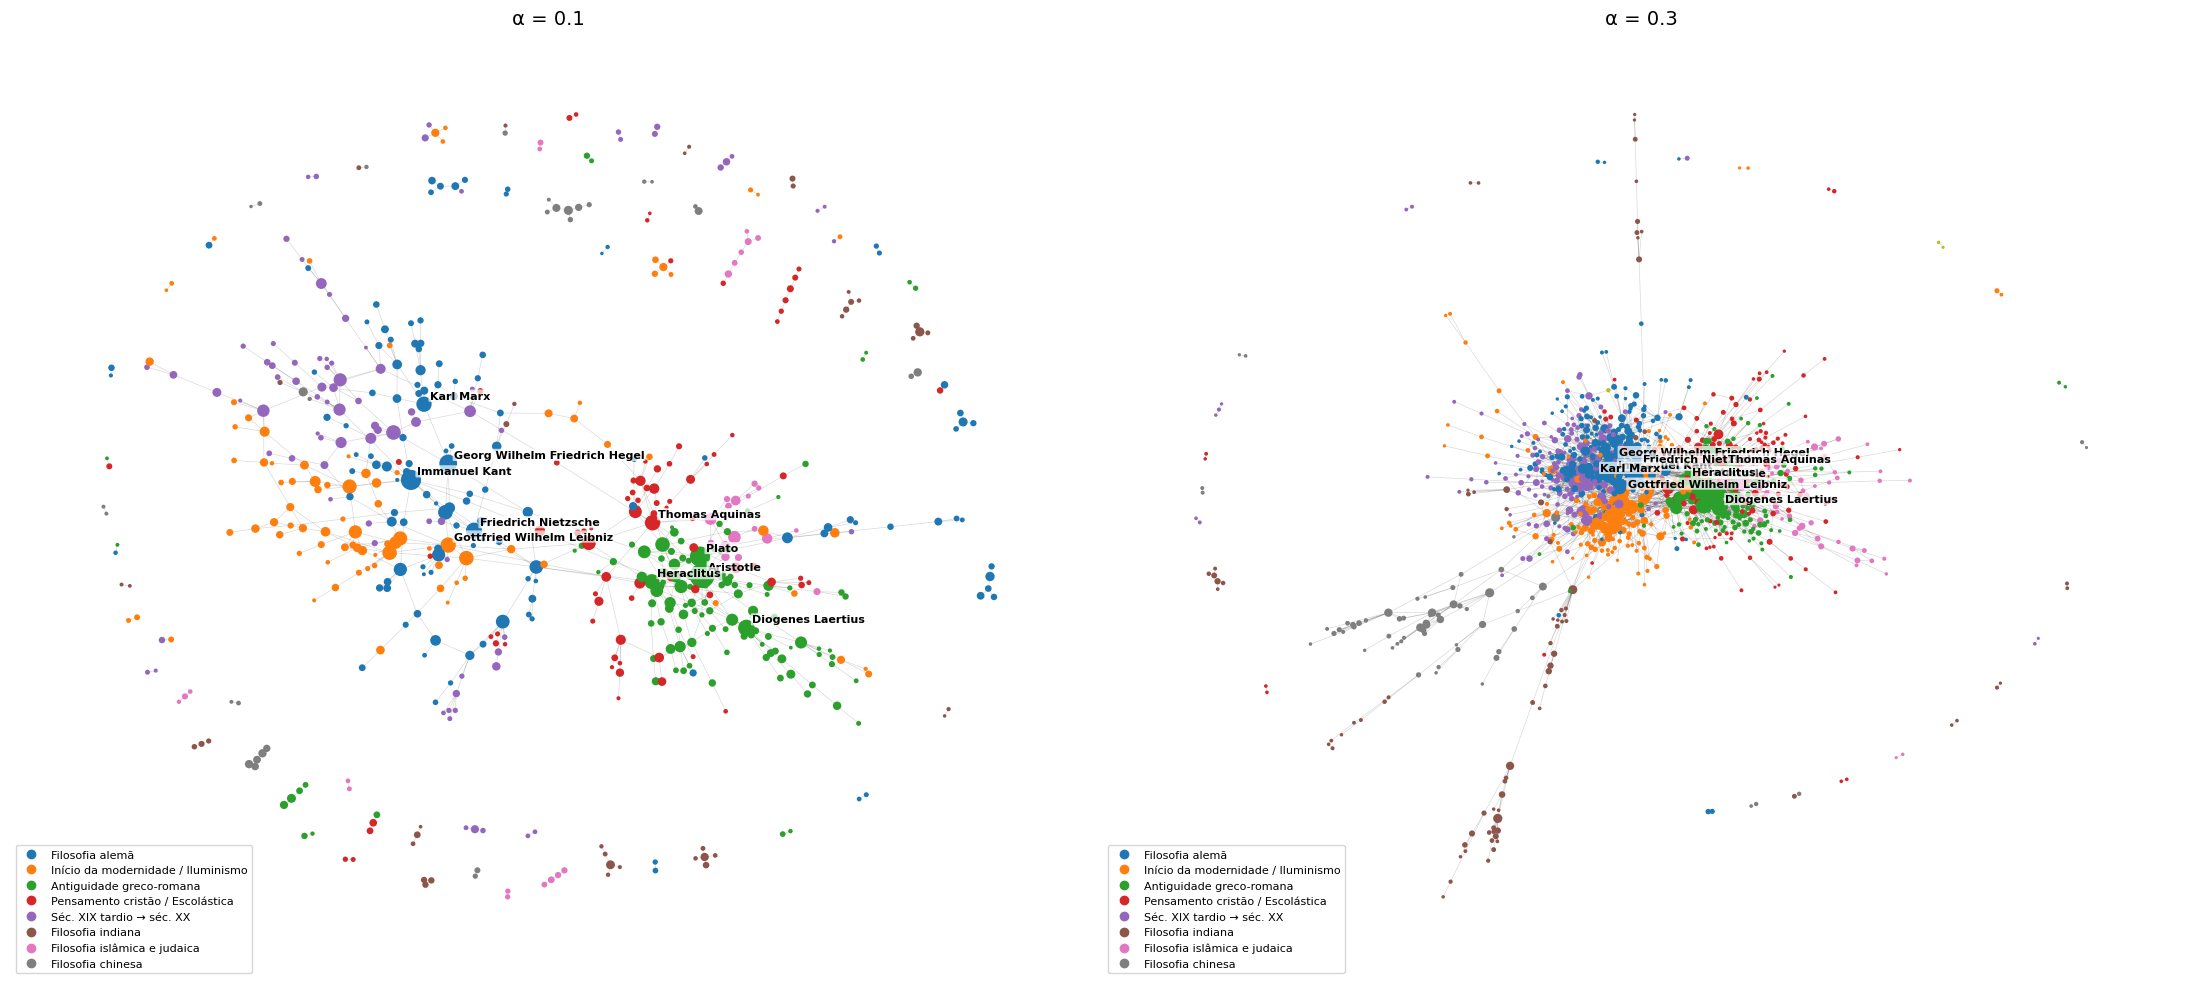

α=0.1: Backbone de disparidade (Serrano et al. 2009), α = 0.1: mantidos 649 de 9139 links (7%); removidos 8490 links e 767 filósofos que ficaram sem nenhuma ligação significativa. Componente gigante do backbone: 419. Layout de força calculado só no backbone; cor = comunidade Louvain na rede completa não pesada (Q = 0.51); tamanho = força; nomes = 10 maiores forças.

α=0.3: Backbone de disparidade (Serrano et al. 2009), α = 0.3: mantidos 2549 de 9139 links (28%); removidos 6590 links e 263 filósofos que ficaram sem nenhuma ligação significativa. Componente gigante do backbone: 1052. Layout de força calculado só no backbone; cor = comunidade Louvain na rede completa não pesada (Q = 0.51); tamanho = força; nomes = 10 maiores forças.



In [ ]:
# 4.11.4 -- α = 0.1 e α = 0.3
caps = {}
fig, axes = plt.subplots(1, 2, figsize=(22, 10))
for ax, a in zip(axes, [0.1, 0.3]):
    caps[a] = draw_backbone(a, ax)
    ax.set_title(f"α = {a}", fontsize=14)
plt.tight_layout(); plt.savefig("figs/4.11_backbone_alpha0.1_0.3.png", dpi=120); plt.show()
for a, c in caps.items(): print(f"α={a}: {c}\n")

**4.11.4 — o que o leitor concluiria.**
- **α = 0.1** (649 links, gigante 419): o leitor vê ilhas bem separadas — as tradições aparecem como
  arquipélagos quase sem pontes, e concluiria que a filosofia é um conjunto de escolas isoladas; mas mais de
  metade dos filósofos desapareceu e as ligações entre tradições (que existem) foram cortadas pelo filtro.
- **α = 0.2** (1540 links, gigante 816): as tradições continuam distinguíveis por cor *e* por posição, mas
  ligadas por pontes plausíveis (Antiguidade → escolástica via Aristóteles/Agostinho; alemães ↔ modernos);
  950 filósofos ficam na figura.
- **α = 0.3** (2549 links, gigante 1052): mais completo, mas começa a voltar a bola de pelo no centro —
  os hubs europeus sobrepõem-se e só as tradições não-europeias se destacam na periferia.

**Para um artigo escolhia α = 0.2**: é o ponto em que o componente gigante ainda contém a maioria dos
filósofos com ligação e a estrutura de grupos ainda se lê a olho; α = 0.1 exagera a separação (sugere uma
fragmentação que é artefacto do filtro) e α = 0.3 esconde-a. E a legenda diria sempre o α e o que foi
removido — como nas legendas geradas acima.

## Exercício 4.12 — Ship an explorable (🚀 builder, stretch, opcional)

> Pick a claim from this week that none of them shows [...] and build the explorable that makes it grabbable, agents encouraged, taste yours.

Não feito aqui (é opcional e é um projeto de JavaScript à parte). **Sugestão com mais potencial de
ensino:** *o limite de resolução* — um anel de cliques $K_5$ ligadas por uma ligação cada; um slider aumenta o
número de cliques e mostra o Louvain a **fundir pares de cliques** assim que o número de ligações internas
de cada uma fica abaixo de $\sqrt{2m}$, com um segundo slider para o parâmetro de resolução $\gamma$. É uma
afirmação da página (Goodies) que nenhum widget mostra, e liga-se diretamente ao 4.6.

## Exercício 4.13 — Go nuts with your LLM (🚀 builder, semanal)

> One free-form post on your group's site, link in this week's Teams channel by Monday evening, friendly criticism for at least one other group. [...] This week the shared network is the philosophers.

Este notebook já tem as peças para duas das aberturas sugeridas:
- **Louvain vs Infomap** (4.9b): o NMI, a tabela de "como o Infomap reparte cada comunidade Louvain", e a
  pergunta "qual conta melhor a história da filosofia?" — um candidato natural é mostrar a comunidade
  alemã do Louvain partida pelo Infomap em idealistas vs académicos (o mesmo corte que o *adaptive cut* faz).
- **O backbone a três α** (4.11.4): encontrar o α em que o componente gigante se parte e **o filósofo cujas
  ligações o partem** (varrer α finamente entre 0.1 e 0.2 e ver que ligação desliga o maior pedaço).

Uma ideia menos "segura": **"Em que tradição está realmente Aristóteles?"** — as comunidades de links do
4.9 dão-lhe dezenas de contextos; uma figura com as ligações dele coloridas por comunidade de link, lado a
lado com a comunidade única que o Louvain lhe atribui, é uma boa história sobre o paradoxo da sobreposição.
*(O post é para o site do grupo — fica por fazer por vocês.)*

## Wrap-up

- **4.1** — edge betweenness por contagem (C–D = 12 → primeiro corte; F–G 6 → 3); dendrograma
  $\{ABC\}\{DEFG\}$ → $\{ABC\}\{DEF\}\{G\}$; porque recalcular. Verificado com `girvan_newman`.
- **4.2** — comunidade vs clique, o papel do termo nulo ($Q_{\text{tudo}} = 0$), "mais agrupado ≠ mais real", as duas perguntas (nulo e estabilidade).
- **4.3** — $Q = 47/128$ vs $7/32$; nível 2 $= 39/128$ ⇒ cortar no nível 1; $Q_{\text{tudo}} = 0$ e partições negativas; prova de que colar a folha ao vizinho dá sempre $\Delta Q = (2m - d_b + d_a')/2m^2 > 0$ (verificada nas 203 partições).
- **4.4** — OpenAlex: 1.66 M / 136 mil / 3 256 resultados, amostras mostram stemming; ~2.5–3.2 mil artigos *sobre* (limite inferior), ~14 mil citam N&G 2004, ~22 mil o Louvain; tema vivo.
- **4.5** — Louvain: 9 comunidades, $Q = 0.506$; nomes; NMI era 0.40 ≫ subfields 0.09; 5 seeds com NMI 0.66–0.78; greedy 15 com $Q = 0.416$; fase 1 escrita de raiz e validada.
- **4.6** — nulos: $Q \approx 0.23$ (graus preservados e $G(n,m)$), $z$ na casa das centenas; ruído puro chega a $Q \approx 0.85$ em redes esparsas mas com NMI baixo; karaté 0.358 / pesado; relatório reescrito.
- **4.7** — $1/14$ vs $11/98$; comunidades de cliques, C em duas, F em nenhuma; B–D faz percolar; $k=4$ vazio; tabela da página reproduzida.
- **4.8** — comunidades de links por olho e por Jaccard; paradoxo da sobreposição.
- **4.9** — link clustering de raiz ($D = 0.054$, 444 comunidades ≥3 links, igual à página) + Infomap; validação com cinco filósofos.
- **4.10** — forças; A→E por saltos vs $1/w$ (desvio por B); $Q_w = 319/722 \approx 0.442$; porque 0.55 vs 0.50 não se compara.
- **4.11** — força vs grau; disparity filter de raiz, tabela da página reproduzida exatamente; figura com as cinco regras a α = 0.2, 0.1, 0.3.
- **4.12 / 4.13** — opcionais / post do grupo: ideias deixadas acima.

**Para o Teste 1**, os que vale a pena refazer em papel sem olhar: 4.1 (contagem de EB), 4.3 (Q por
comunidade com denominador comum), 4.7.2–3 (cliques e percolação), 4.10 (força, Dijkstra com $1/w$,
$Q$ pesado) e uma aplicação do teste de disparidade a uma ligação (o exemplo de Moses of Narbonne).